<center><h1>Satish_Manvika_HW4</h1></center>
<br>
Name: Manvika Satish
<br>
Github Username: manvsatish 
<br>
USC ID: 5582061880

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import io
import re
import warnings
import zipfile
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm

from sklearn.base import clone
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize

In [2]:
RANDOM_STATE = 552
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

Get the AReM Data Set

In [3]:
zip_path = Path("../data/AReM.zip") #relative path
print("ZIP file exists:", zip_path.exists())
print("Relative path:", zip_path)
assert zip_path.exists(), f"Data file not found at {zip_path}"

#valid csv files
with zipfile.ZipFile(zip_path, "r") as archive:
    csv_files = sorted(name for name in archive.namelist() if name.endswith(".csv") and "__MACOSX" not in name)

print("Number of CSV files:", len(csv_files))
print("First five files:")
for name in csv_files[:5]:
    print(name)

assert len(csv_files) == 88, (f"Expected 88 CSV files, found {len(csv_files)}")

ZIP file exists: True
Relative path: ../data/AReM.zip
Number of CSV files: 88
First five files:
AReM/bending1/dataset1.csv
AReM/bending1/dataset2.csv
AReM/bending1/dataset3.csv
AReM/bending1/dataset4.csv
AReM/bending1/dataset5.csv


In [4]:
#col names used by every cleaned arem instance
column_names = ["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23",]

# should contain timestamps from 0 to 119750 in increments of 250 = 480 obs
expected_times = np.arange(0, 120000, 250)

#read and clean one csv file directly from zip
def read_activity_csv(archive, member_name):
    #deode the file without extracting it to the filesystem
    text = archive.read(member_name).decode("utf-8", errors="replace",)
    rows = []

    for line in text.splitlines():
        line = line.strip()
        if not line or line.startswith("#"):
            continue

        #most files are comma-delimited, bending2/dataset4.csv is whitespace-delimited.
        parts = line.split(",") if "," in line else line.split()
        parts = [part.strip() for part in parts if part.strip()] # remove empty fields produced by trailing commas

        # ignore rows that do not contain all seven required values.
        if len(parts) < 7:
            continue
        try:
            rows.append([float(value) for value in parts[:7]])
        except ValueError:
            continue # ignore any remaining nonnumeric header row

    data = pd.DataFrame(rows, columns=column_names)
    original_rows = len(data)

    # standard timestamp type and combine duplicate timestamps if any are there
    data["time"] = data["time"].astype(int)
    data = data.groupby("time", as_index=False).mean()

    #find missing expected timestamps before fixing
    missing_times = sorted(set(expected_times) - set(data["time"]))
    needs_repair = (len(data) != len(expected_times) or not np.array_equal(data["time"].to_numpy(), expected_times,))

    # sitting/dataset8.csv is missing timestamp 13500
    # restore missing observations using linear interpolation.
    if needs_repair:
        data = (data.set_index("time").reindex(expected_times).interpolate(method="linear", limit_direction="both",).rename_axis("time").reset_index())

    # check for no missing vals
    assert data.shape == (480, 7), (f"{member_name} has unexpected shape {data.shape}")
    assert not data.isna().any().any(), (f"{member_name} still contains missing values")

    cleaning_info = {"file": member_name, "original_rows": original_rows, "final_rows": len(data), "missing_times": missing_times, "repaired": needs_repair,}
    
    return data, cleaning_info

### (b) Splitting Data

In [5]:
activity_order = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking",]

#sort archive members by activity and numeric ds number
def file_sort_key(member_name):
    activity = Path(member_name).parent.name
    dataset_number = int(re.search(r"dataset(\d+)\.csv$", member_name,).group(1))

    return activity_order.index(activity), dataset_number

# store cleaned activity instance and its split assignment
instances = []
cleaning_records = []

with zipfile.ZipFile(zip_path, "r") as archive:
    for member_name in sorted(csv_files, key=file_sort_key,):
        activity = Path(member_name).parent.name
        dataset_number = int(re.search(r"dataset(\d+)\.csv$", member_name,).group(1))

        # read and clean current
        data, cleaning_info = read_activity_csv(archive, member_name,)

        if activity in {"bending1", "bending2"}:
            split = ("test" if dataset_number in {1, 2} else "train") # datasets 1 and 2 - test data
        else:
            split = ("test" if dataset_number in {1, 2, 3} else "train") # datasets 1, 2, 3 are test data - all other classes

        instances.append({"activity": activity, "dataset": dataset_number, "split": split, "data": data,})
        cleaning_info.update({"activity": activity, "dataset": dataset_number,})
        cleaning_records.append(cleaning_info)

# check if every dataset was loaded exactly once
assert len(instances) == 88

# summ the train/test split by activity
split_summary = (pd.DataFrame(instances).groupby(["activity", "split"]).size().unstack(fill_value=0).sort_index())
split_summary.loc["Total"] = split_summary.sum()

# files that need timestamp repair
cleaning_summary = pd.DataFrame(cleaning_records)
repaired_files = cleaning_summary.loc[cleaning_summary["repaired"], ["activity", "dataset", "original_rows", "final_rows", "missing_times",],]

print("Total instances loaded:", len(instances))
print("\nFiles requiring timestamp repair:")
display(repaired_files)

print("\nTrain/test split:")
display(split_summary)

Total instances loaded: 88

Files requiring timestamp repair:


,activity,dataset,original_rows,final_rows,missing_times
50,sitting,8,479,480,[13500]



Train/test split:


split,test,train
activity,,
bending1,2,5
bending2,2,4
cycling,3,12
lying,3,12
sitting,3,12
standing,3,12
walking,3,12
Total,19,69


### (c) Feature Extraction

In [6]:
sensor_columns = column_names[1:]

#split six time series into ~ equal segments, extract seven time domain fts from every segment
def extract_segmented_features(data, number_of_segments):
    features = {}

    for series_number, column in enumerate(sensor_columns,start=1,):
        segments = np.array_split(data[column].to_numpy(), number_of_segments,)
        for segment_number, segment in enumerate(segments, start=1,):
            feature_prefix = (
                f"series{series_number}_"
                f"segment{segment_number}"
            )

            features[f"{feature_prefix}_min"] = np.min(segment)
            features[f"{feature_prefix}_max"] = np.max(segment)
            features[f"{feature_prefix}_mean"] = np.mean(segment)
            features[f"{feature_prefix}_median"] = np.median(segment)
            features[f"{feature_prefix}_std"] = np.std(segment, ddof=1,)
            features[f"{feature_prefix}_1st_quart"] = np.quantile(segment, 0.25,)
            features[f"{feature_prefix}_3rd_quart"] = np.quantile(segment, 0.75,)
    return features


# feature matrix & labels for l
def build_feature_dataset(instance_list, number_of_segments):
    feature_rows = []
    metadata_rows = []

    for instance_number, instance in enumerate(instance_list, start=1,):
        # extract 42*l time domain features for instance
        feature_rows.append(extract_segmented_features(instance["data"], number_of_segments,))

        # store labels and identifiers separately from num fts
        metadata_rows.append(
            {
                "instance": instance_number,
                "activity": instance["activity"],
                "dataset": instance["dataset"],
                "split": instance["split"],
                "binary_label": int(
                    instance["activity"]
                    in {"bending1", "bending2"}
                ),
            }
        )

    feature_matrix = pd.DataFrame(feature_rows)
    metadata = pd.DataFrame(metadata_rows)

    # six series contributes seven features per segment
    expected_feature_count = 6 * 7 * number_of_segments

    assert feature_matrix.shape == (len(instance_list), expected_feature_count,)
    assert not feature_matrix.isna().any().any()

    return feature_matrix, metadata


# verify extractor for l=1 and 2
features_l1, metadata_l1 = build_feature_dataset(instances, number_of_segments=1,)
features_l2, metadata_l2 = build_feature_dataset(instances, number_of_segments=2,)
print("l=1 feature shape:", features_l1.shape)
print("l=2 feature shape:", features_l2.shape)

# confirm metadata preserves the required split
print("\nSplit counts:")
display(metadata_l1["split"].value_counts())

l=1 feature shape: (88, 42)
l=2 feature shape: (88, 84)

Split counts:


split
train    69
test     19
Name: count, dtype: int64

For each value of \(l\), I split each of the six time series into \(l\) approximately equal segments using `numpy.array_split`. Then, I extracted the minimum, maximum, mean, median, sample standard deviation, first quartile, and third quartile from every segment. So, each instance has \(6 \times l \times 7 = 42l\) features. The train/test assignment stays unchanged when the number of segments changes.

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

For the three important time-domain features in 1(c)(iv), I selected the minimum, mean, and maximum. I use these features from time series 1, 2, and 6 in the following plots.

Binary training-class counts:


Other      60
Bending     9
Name: count, dtype: int64

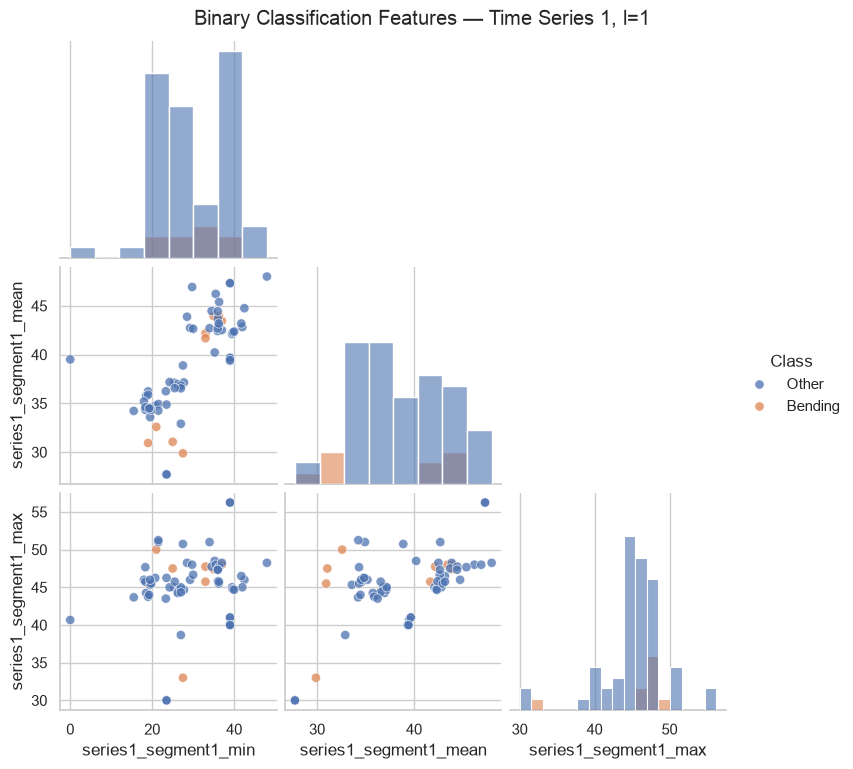

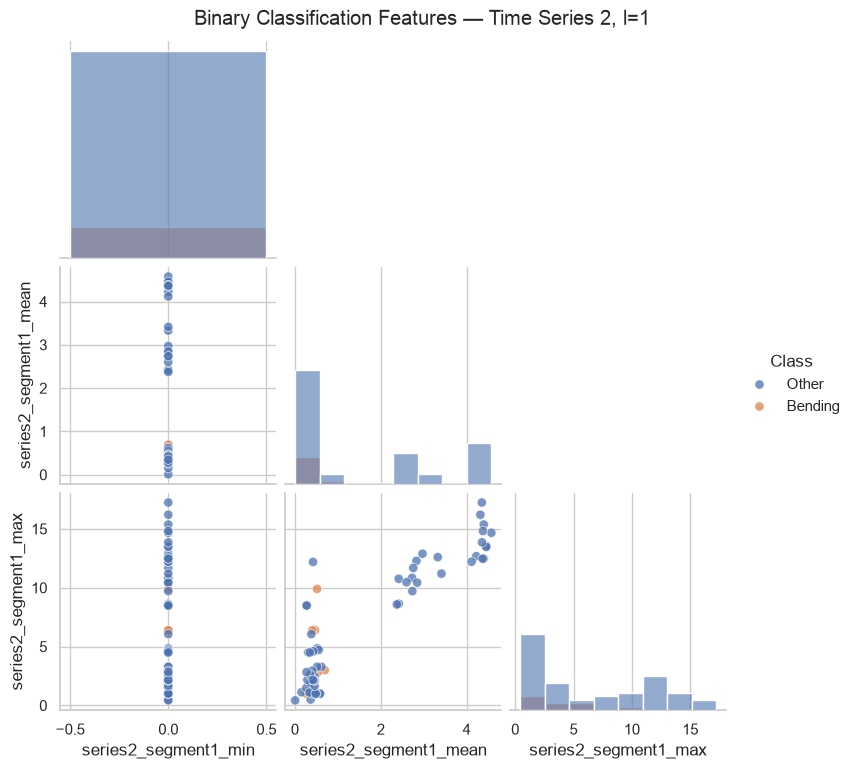

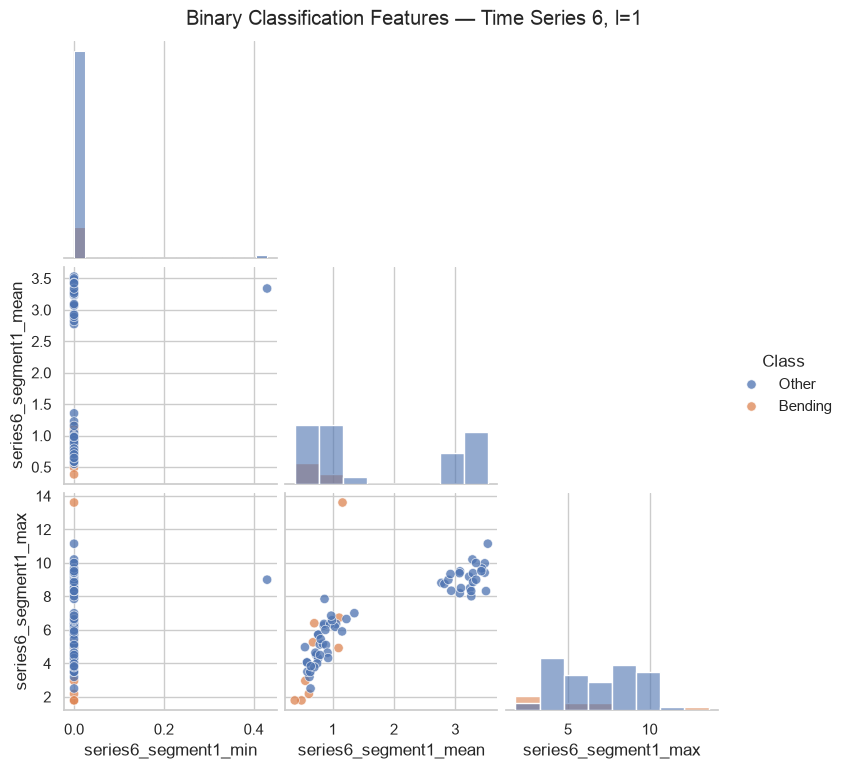

In [7]:
# using only the training instances for model dev & plotting
train_mask = metadata_l1["split"].eq("train")

X_train_l1 = features_l1.loc[train_mask].reset_index(drop=True)
y_train_binary = (metadata_l1.loc[train_mask, "binary_label"].reset_index(drop=True))

# class distr in training data
binary_class_counts = (pd.Series(np.where(y_train_binary.eq(1), "Bending", "Other",)).value_counts())
print("Binary training-class counts:")
display(binary_class_counts)

# minimum, mean, and maximum from hw3 selection
selected_statistics = ["min", "mean", "max"]
selected_series = [1, 2, 6]

for series_number in selected_series:
    selected_columns = [f"series{series_number}_segment1_{statistic}" for statistic in selected_statistics]

    plot_data = X_train_l1[selected_columns].copy()
    plot_data["Class"] = np.where(y_train_binary.eq(1), "Bending", "Other",)

    plot_grid = sns.pairplot(plot_data, vars=selected_columns, hue="Class", hue_order=["Other", "Bending"], corner=True, diag_kind="hist", plot_kws={"alpha": 0.75, "s": 45,}, diag_kws={"alpha": 0.60,},)
    plot_grid.figure.suptitle(
        (
            "Binary Classification Features — "
            f"Time Series {series_number}, l=1"
        ),
        y=1.02,
    )

    plt.show()

The training set contains 9 bending instances and 60 non-bending instances, so the binary classes are imbalanced. The features from time series 1 give some distinction because many of the bending instances have lower min and mean values, although there is still a good amount of overlap. The min values for time series 2 and 6 are almost always zero, so those two minimum features provide little discriminatory information. Some separation is visible in the mean and maximum of time series 6, but none of the three feature groups completely separates bending from the other activities.

#### ii. Splitted Plots

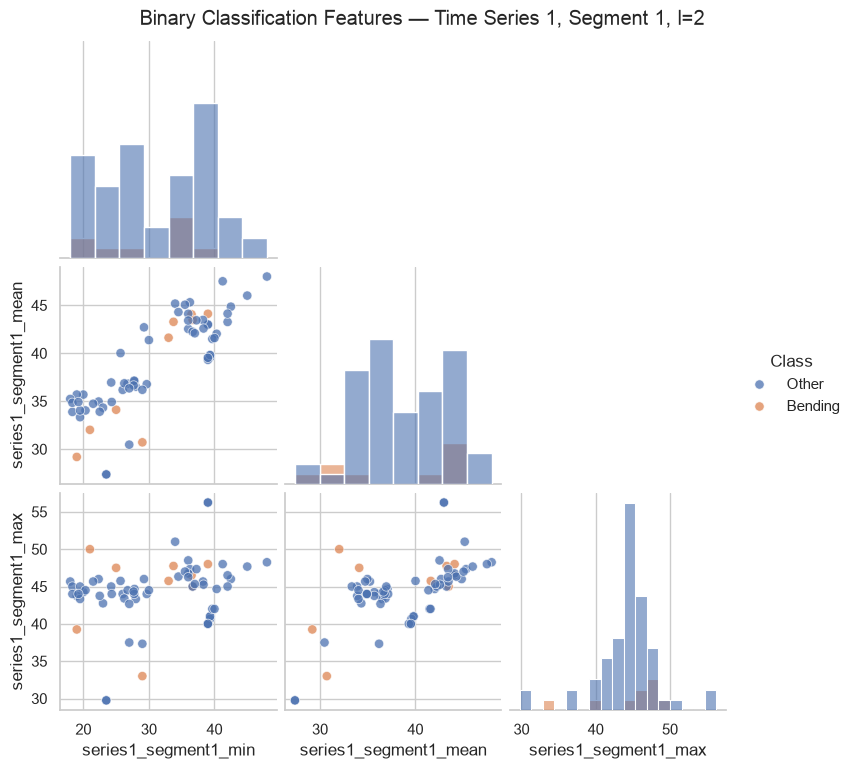

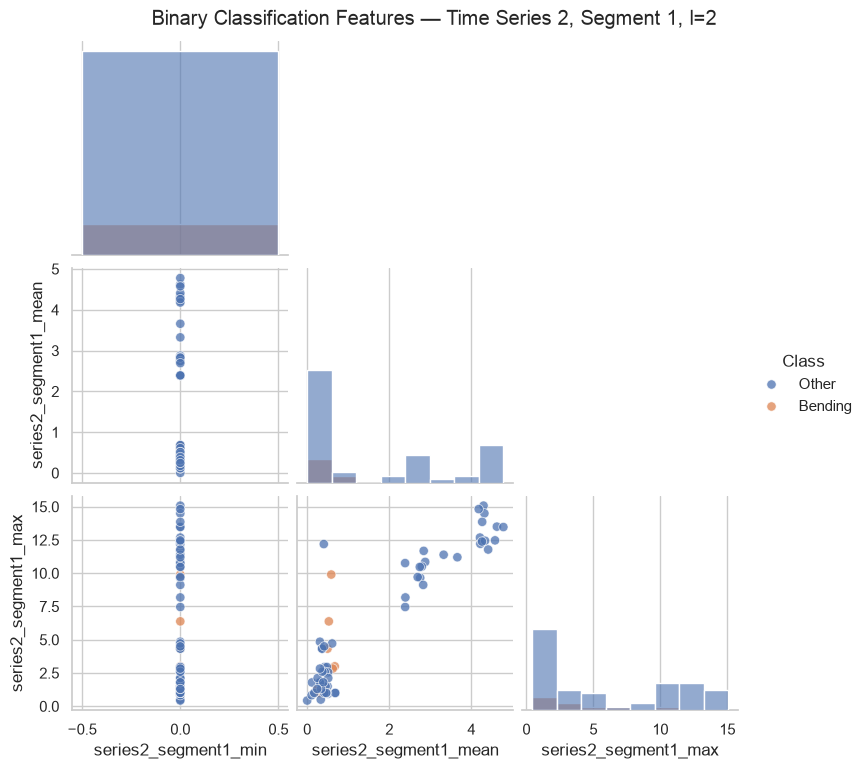

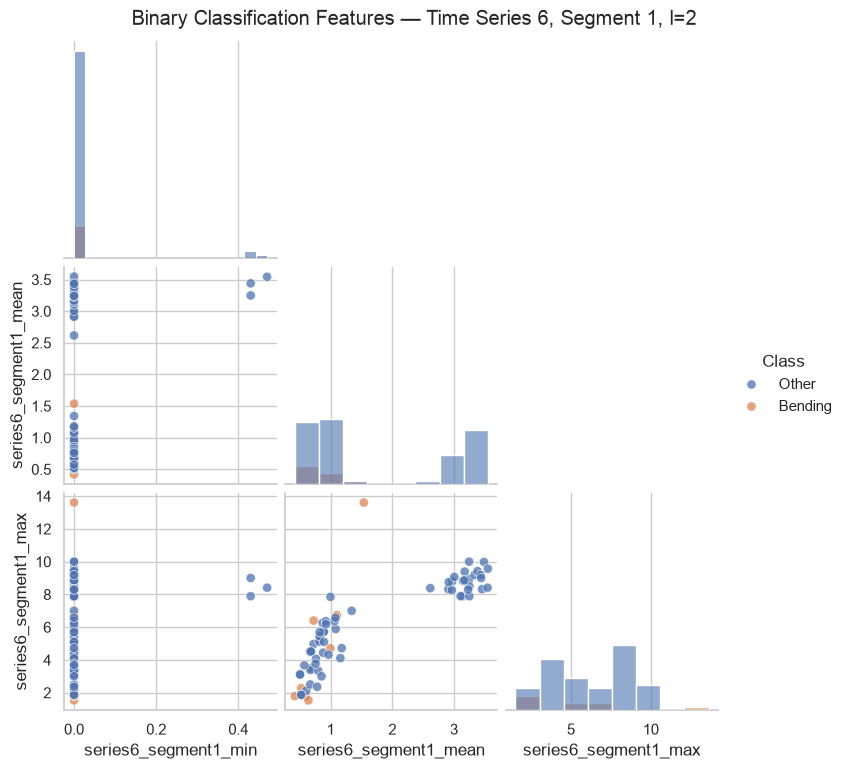

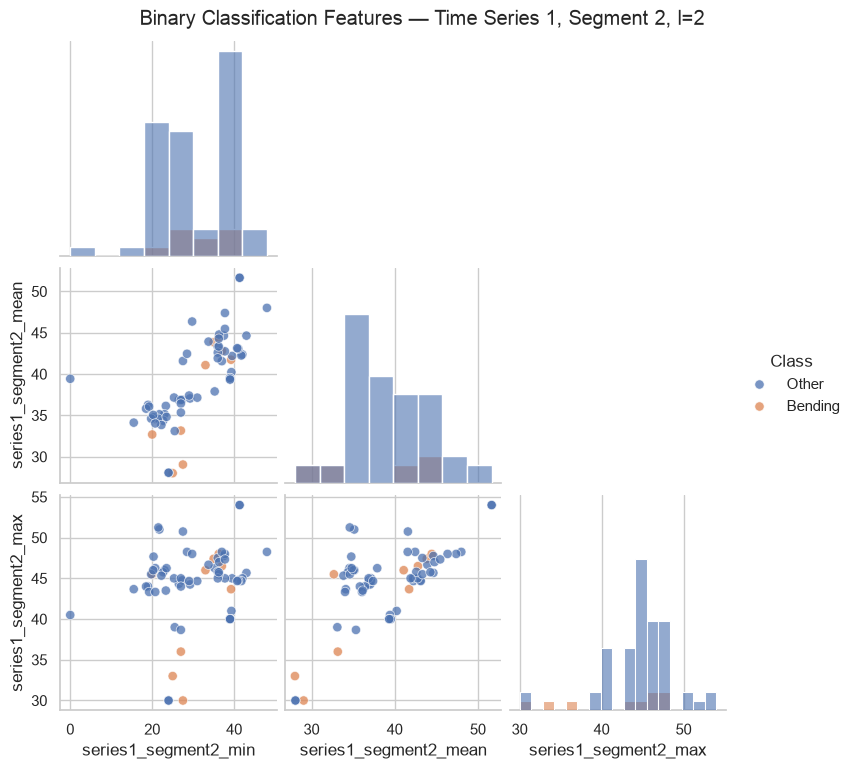

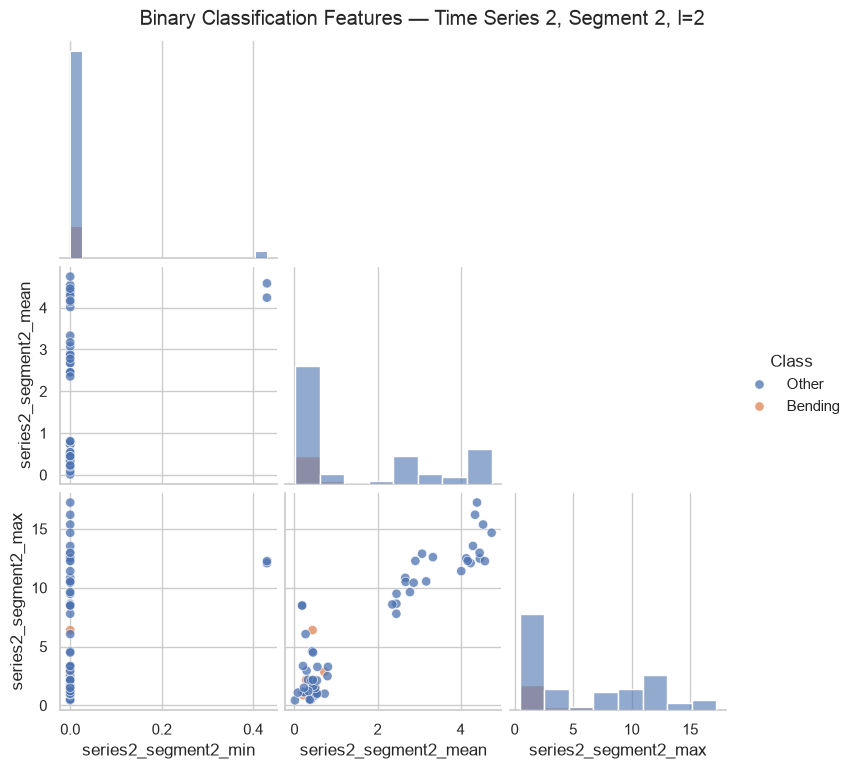

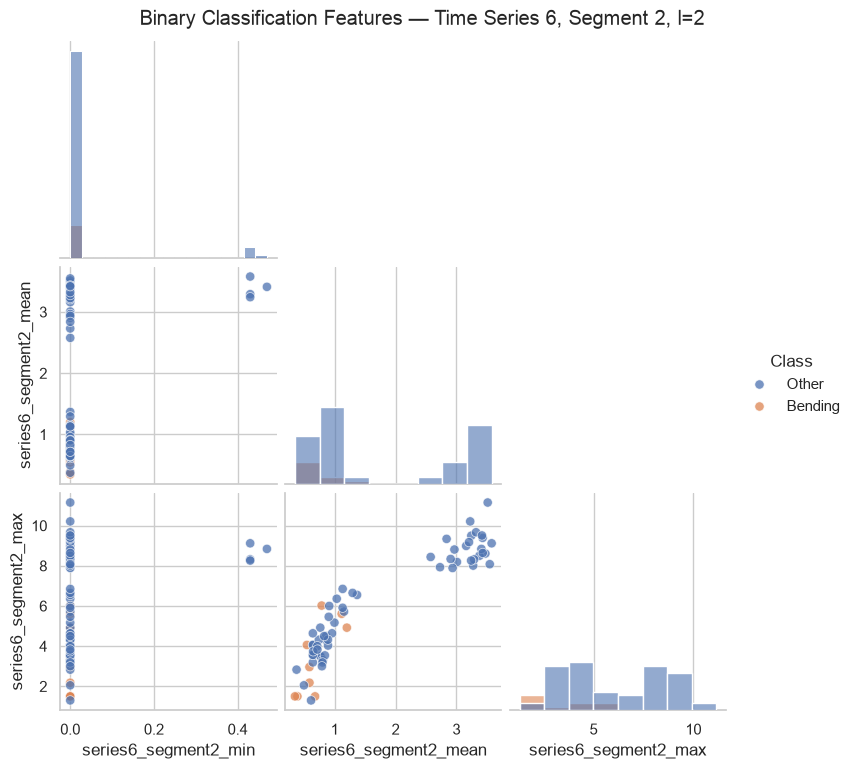

In [8]:
# training l=2 feature matrix
train_mask_l2 = metadata_l2["split"].eq("train")

X_train_l2 = (features_l2.loc[train_mask_l2].reset_index(drop=True))
y_train_binary_l2 = (metadata_l2.loc[train_mask_l2, "binary_label"].reset_index(drop=True))

# scatter-plot matrices for both segments of time series 1, 2, and 6
for segment_number in [1, 2]:
    for series_number in selected_series:
        selected_columns = [
            (
                f"series{series_number}_"
                f"segment{segment_number}_{statistic}"
            )
            for statistic in selected_statistics
        ]

        plot_data = X_train_l2[selected_columns].copy()
        plot_data["Class"] = np.where(y_train_binary_l2.eq(1), "Bending", "Other",)
        plot_grid = sns.pairplot(plot_data, vars=selected_columns, hue="Class", hue_order=["Other", "Bending"], corner=True, diag_kind="hist", plot_kws={"alpha": 0.75, "s": 45,}, diag_kws={"alpha": 0.60,},)
        plot_grid.figure.suptitle(
            (
                "Binary Classification Features — "
                f"Time Series {series_number}, "
                f"Segment {segment_number}, l=2"
            ),
            y=1.02,
        )

        plt.show()

Splitting each time series into two parts keeps some local temporal information that was averaged together when \(l=1\). The two segments of time series 1 show somewhat different distributions, and some bending observations have lower min and mean values than most non-bending observations. But there is a substantial overlap in both segments. The min features from time series 2 and 6 are still nearly always zero and still therefore remain weak predictors. Overall, \(l=2\) provides additional local information, but the plots don't show a dramatic improvement in visual class separation compared with \(l=1\).

#### iii. Time Series Segments

For each $l \in \{1,\ldots,20\}$, I create a different feature matrix containing $42l$ features. I use stratified five-fold cross-validation because the bending class has only 9 training instances, while the non-bending class has 60. Stratification preserves approximately the same proportion of bending and non-bending observations in every fold, helping ensure that every validation fold includes observations from the minority class.

The wrong approach would be to scale the features or perform recursive feature elimination on the complete training set before cross-validation. That would allow information from the validation folds to influence feature selection and would produce an optimistically biased validation score.

The correct approach is to place scaling, recursive feature elimination, and logistic regression in a single pipeline. During cross-validation, each step is fitted only on the current training fold and then applied to the unseen validation fold. I search $p \in \{1,\ldots,20\}$, limiting the number of selected features because there are only 9 positive training instances.

In [9]:
#identical stratified folds for every value of l
binary_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE,)
segmented_feature_cache = {}
binary_best_estimators = {}
binary_cv_rows = []

# every allowed number of time-series segments
for number_of_segments in range(1, 21):
    # construct 42*l feature matrix
    feature_matrix, metadata = build_feature_dataset(instances, number_of_segments=number_of_segments,)
    segmented_feature_cache[number_of_segments] = (feature_matrix, metadata,)

    #training instances during model selection
    training_mask = metadata["split"].eq("train")
    X_train = (feature_matrix.loc[training_mask].reset_index(drop=True))
    y_train = (metadata.loc[training_mask, "binary_label"].reset_index(drop=True))

    # p=1,...,20, all l values >= 42 features
    candidate_feature_counts = list(range(1, 21))

    # unpenalized logistic regression for feature ranking & final classifier
    rfe_estimator = LogisticRegression(C=np.inf, solver="lbfgs", max_iter=10000, random_state=RANDOM_STATE,)
    final_estimator = LogisticRegression(C=np.inf, solver="lbfgs", max_iter=10000, random_state=RANDOM_STATE,)

    # fitted separately within every cross-validation fold
    binary_pipeline = Pipeline(steps=[("scaler", StandardScaler()), ("rfe", RFE(estimator=rfe_estimator, n_features_to_select=1, step=0.5,),), ("classifier", final_estimator),])

    # best number of retained features for this l
    binary_search = GridSearchCV(estimator=binary_pipeline, param_grid={"rfe__n_features_to_select": (candidate_feature_counts)}, scoring="accuracy", cv=binary_cv, n_jobs=-1, refit=True, error_score="raise",)
    binary_search.fit(X_train, y_train)

    best_feature_count = (binary_search.best_params_["rfe__n_features_to_select"])
    binary_best_estimators[number_of_segments] = (binary_search.best_estimator_)

    binary_cv_rows.append({"l": number_of_segments,"p": best_feature_count, "Mean CV Accuracy": (binary_search.best_score_), "CV Standard Deviation": (binary_search.cv_results_["std_test_score"][binary_search.best_index_]),})
    print(
        f"Completed l={number_of_segments:2d}: "
        f"best p={best_feature_count:2d}, "
        f"CV accuracy={binary_search.best_score_:.4f}"
    )

# compare the best feature count for every val of l
binary_cv_results = pd.DataFrame(binary_cv_rows)

# prefer fewer segments and fewer features
binary_cv_results = binary_cv_results.sort_values(by=["Mean CV Accuracy", "l", "p"], ascending=[False, True, True],).reset_index(drop=True)
best_binary_row = binary_cv_results.iloc[0]
best_binary_l = int(best_binary_row["l"])
best_binary_p = int(best_binary_row["p"])
best_binary_cv_accuracy = float(best_binary_row["Mean CV Accuracy"])
best_binary_pipeline = binary_best_estimators[best_binary_l]

print("\nBest binary model:")
print("Best l:", best_binary_l)
print("Best p:", best_binary_p)
print("Best mean CV accuracy:", round(best_binary_cv_accuracy, 4),)

display(binary_cv_results.sort_values("l").reset_index(drop=True).round(4))

Completed l= 1: best p= 3, CV accuracy=0.9857
Completed l= 2: best p= 6, CV accuracy=0.9714
Completed l= 3: best p= 3, CV accuracy=0.9571
Completed l= 4: best p= 3, CV accuracy=0.9571
Completed l= 5: best p= 4, CV accuracy=0.9286
Completed l= 6: best p= 3, CV accuracy=0.9571
Completed l= 7: best p= 4, CV accuracy=0.9286
Completed l= 8: best p=17, CV accuracy=0.9571
Completed l= 9: best p= 2, CV accuracy=0.9429
Completed l=10: best p= 9, CV accuracy=0.9429
Completed l=11: best p=10, CV accuracy=0.9418
Completed l=12: best p= 7, CV accuracy=0.9571
Completed l=13: best p= 4, CV accuracy=0.9429
Completed l=14: best p= 4, CV accuracy=0.9429
Completed l=15: best p=19, CV accuracy=0.9429
Completed l=16: best p= 4, CV accuracy=0.9143
Completed l=17: best p=13, CV accuracy=0.9571
Completed l=18: best p=20, CV accuracy=0.9714
Completed l=19: best p=15, CV accuracy=0.9571
Completed l=20: best p= 7, CV accuracy=0.9714

Best binary model:
Best l: 1
Best p: 3
Best mean CV accuracy: 0.9857


,l,p,Mean CV Accuracy,CV Standard Deviation
0,1,3,0.9857,0.0286
1,2,6,0.9714,0.0350
2,3,3,0.9571,0.0350
3,4,3,0.9571,0.0571
4,5,4,0.9286,0.0639
5,6,3,0.9571,0.0350
6,7,4,0.9286,0.0782
7,8,17,0.9571,0.0571
8,9,2,0.9429,0.0286
9,10,9,0.9429,0.0700


The cross-validation search selected \(l=1\) and \(p=3\), with a mean validation accuracy of about 0.9857 and a standard deviation of about 0.0286. Increasing \(l\) didn't improve validation accuracy, showing that the additional segment-level features increase model complexity without providing enough additional predictive information for this small training set.

#### iv. Confusion Matrix

Training accuracy: 1.0
Training AUC: 1.0
Training confusion matrix:


,Predicted Other,Predicted Bending
Actual Other,60,0
Actual Bending,0,9


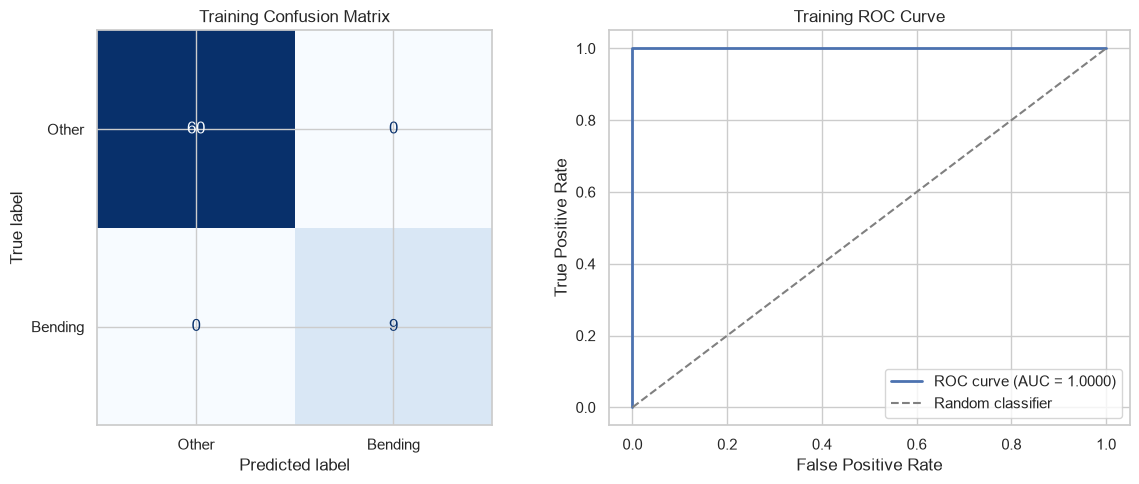

Selected features:
- series1_segment1_3rd_quart
- series5_segment1_min
- series5_segment1_max

Coefficient and p-value note:
Classical p-values could not be estimated because the unpenalized logistic model produced a singular Hessian. This is evidence of complete or quasi-complete separation.


,Coefficient,P-value
Intercept,-26.258461,NaN
series1_segment1_3rd_quart,-7.788428,NaN
series5_segment1_min,13.084306,NaN
series5_segment1_max,16.405057,NaN


In [10]:
#feature matrix corresponding to the selected l
best_feature_matrix, best_metadata = (segmented_feature_cache[best_binary_l])
best_training_mask = best_metadata["split"].eq("train")

X_train_best = (best_feature_matrix.loc[best_training_mask].reset_index(drop=True))
y_train_best = (best_metadata.loc[best_training_mask, "binary_label",].reset_index(drop=True))

#best pipeline was already refitted on the complete training set
train_predictions = best_binary_pipeline.predict(X_train_best)
train_probabilities = (best_binary_pipeline.predict_proba(X_train_best)[:, 1])
train_accuracy = accuracy_score(y_train_best,train_predictions,)
train_confusion = confusion_matrix(y_train_best, train_predictions,)
train_auc = roc_auc_score(y_train_best, train_probabilities,)
train_fpr, train_tpr, _ = roc_curve(y_train_best, train_probabilities,)

print("Training accuracy:", round(train_accuracy, 4))
print("Training AUC:", round(train_auc, 4))
print("Training confusion matrix:")
display(pd.DataFrame(train_confusion, index=["Actual Other", "Actual Bending"], columns=["Predicted Other", "Predicted Bending",],))

# confusion matrix and ROC curve plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5),)
ConfusionMatrixDisplay(confusion_matrix=train_confusion, display_labels=["Other", "Bending"],).plot(ax=axes[0], cmap="Blues", colorbar=False,)
axes[0].set_title("Training Confusion Matrix")
axes[1].plot(train_fpr, train_tpr, linewidth=2, label=f"ROC curve (AUC = {train_auc:.4f})",)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier",)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Training ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

#features retained by RFE
fitted_scaler = best_binary_pipeline.named_steps["scaler"]
fitted_rfe = best_binary_pipeline.named_steps["rfe"]
selected_feature_mask = fitted_rfe.support_
selected_feature_names = X_train_best.columns[selected_feature_mask].tolist()

# reproduce pipeline transformations for statsmodels
X_train_scaled = fitted_scaler.transform(X_train_best)
X_train_selected = fitted_rfe.transform(X_train_scaled)

# extract the coefficients fitted by the final sklearn classifier whcih correspond to the standardized, rfe selected features
fitted_classifier = best_binary_pipeline.named_steps["classifier"]
coefficient_names = ["Intercept", *selected_feature_names]
sklearn_coefficients = np.concatenate([fitted_classifier.intercept_, fitted_classifier.coef_.ravel(),])

#max-likelihood p-values with Statsmodels.
statsmodels_design = sm.add_constant(X_train_selected, has_constant="add",)

try:
    statsmodels_logit = sm.Logit(y_train_best.to_numpy(), statsmodels_design,)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        statsmodels_result = statsmodels_logit.fit(disp=False, maxiter=10000,)

    p_values = statsmodels_result.pvalues
    p_value_note = ("Statsmodels successfully estimated the classical p-values.")

except (np.linalg.LinAlgError, Exception) as error:
    # under complete or quasi-complete separation the max-likelihood covariance matrix is singular, so ordinary p-values are undef
    p_values = np.full(len(coefficient_names), np.nan)
    p_value_note = (
        "Classical p-values could not be estimated because the "
        "unpenalized logistic model produced a singular Hessian. "
        "This is evidence of complete or quasi-complete separation."
    )

coefficient_table = pd.DataFrame({"Coefficient": sklearn_coefficients, "P-value": p_values,}, index=coefficient_names,)

print("Selected features:")
for feature_name in selected_feature_names:
    print("-", feature_name)
print("\nCoefficient and p-value note:")
print(p_value_note)
display(coefficient_table.round(6))

The ordinary unpenalized logistic-regression p-values couldn't be estimated because the Hessian matrix was singular. This happens when the
selected predictors output complete or quasi-complete separation. In that situation, finite maximum-likelihood coefficient estimates and their usual standard errors and p-values don't exist. The table therefore reports the coefficients from the fitted scikit-learn model and marks the classical p-values as unavailable.

#### v. Test Classifier

I now evaluate the selected logistic-regression model on the original test set. The test instances were not used during feature selection, cross-validation, or model fitting. I use the same selected value of $l$ and the pipeline fitted on the training data.

Selected l: 1
Selected p: 3
Mean cross-validation accuracy: 0.9857
Test accuracy: 1.0
Test AUC: 1.0

Test confusion matrix:


,Predicted Other,Predicted Bending
Actual Other,15,0
Actual Bending,0,4


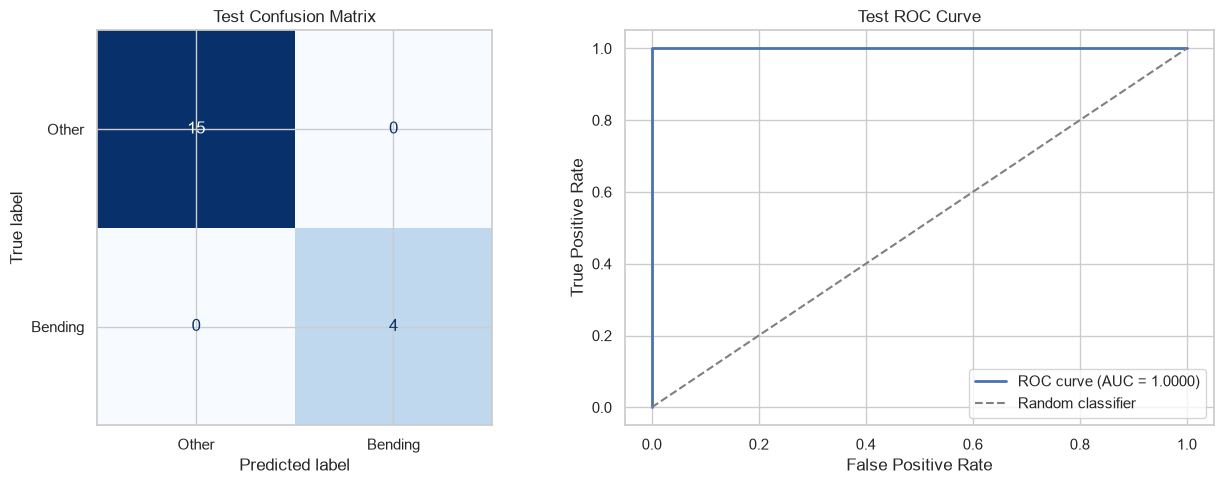


Test accuracy minus mean CV accuracy: 0.0143


In [11]:
# choose only the held-out test instances from the feature matrix corresponding to the best value of l
test_mask = best_metadata["split"].eq("test")
X_test_best = (best_feature_matrix.loc[test_mask].reset_index(drop=True))
y_test_best = (best_metadata.loc[test_mask, "binary_label"].reset_index(drop=True))

#complete fitted pipeline to the untouched test set
# The pipeline performs scaling, RFE selection, and classification.
test_predictions = best_binary_pipeline.predict(X_test_best)
test_probabilities = best_binary_pipeline.predict_proba(X_test_best)[:, 1]

# test-set classification metrics
test_accuracy = accuracy_score(y_test_best, test_predictions,)
test_auc = roc_auc_score(y_test_best, test_probabilities,)
test_confusion = confusion_matrix(y_test_best, test_predictions, labels=[0, 1],)
test_confusion_table = pd.DataFrame(test_confusion, index=["Actual Other", "Actual Bending"], columns=["Predicted Other", "Predicted Bending"],)

print("Selected l:", best_binary_l)
print("Selected p:", best_binary_p)
print("Mean cross-validation accuracy:", round(best_binary_cv_accuracy, 4))
print("Test accuracy:", round(test_accuracy, 4))
print("Test AUC:", round(test_auc, 4))
print("\nTest confusion matrix:")

display(test_confusion_table)

# points needed for the test ROC curve.
test_false_positive_rate, test_true_positive_rate, _ = roc_curve(y_test_best, test_probabilities,)

# test confusion matrix and ROC curve together.
figure, axes = plt.subplots(1, 2, figsize=(13, 5),)
ConfusionMatrixDisplay(confusion_matrix=test_confusion, display_labels=["Other", "Bending"],).plot(ax=axes[0], cmap="Blues", colorbar=False,)

axes[0].set_title("Test Confusion Matrix")
axes[1].plot(test_false_positive_rate, test_true_positive_rate, linewidth=2, label=f"ROC curve (AUC = {test_auc:.4f})",)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier",)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Test ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

# held-out result vs cross-validation estimate
accuracy_difference = test_accuracy - best_binary_cv_accuracy
print("\nTest accuracy minus mean CV accuracy:", round(accuracy_difference, 4),)

The selected model uses $l=1$ and $p=3$. It correctly classified all 19 test instances, including 15 non-bending and 4 bending instances. Therefore, its test accuracy and test AUC are both 1.0000. The mean five-fold cross-validation accuracy was 0.9857, whereas the test accuracy was 1.0000. Thus, the test accuracy is 0.0143, or 1.43 percentage points, higher than the cross-validation estimate. The two results are close, although the test set is small, so the perfect test accuracy should be interpreted cautiously.

#### vi. Separation

##### Do your classes seem to be well-separated to cause instability in calculating logistic regression parameters?
Yes, the two classes appear to be completely or nearly completely separated by the selected features. The logistic-regression model classified every training instance correctly, outputting a training accuracy and AUC of 1.0000. It also classified every test instance
correctly. Further evidence of separation happened when I tried to estimate the model with Statsmodels. The Hessian matrix was singular, so the usual coefficient standard errors and p-values couldn't be calculated. Under complete separation, the unpenalized maximum-likelihood coefficients tend toward very large magnitudes instead of converging to stable finite values. Therefore, although the classifier performs well, its unpenalized coefficient estimates and classical p-values are unstable.

#### vii. Imbalance

The training data are imbalanced because they contain 60 non-bending instances and only 9 bending instances. I use case-control sampling by retaining all 9 bending instances and randomly selecting 9 non-bending instances. Because this produces an artificial class proportion of 0.5, I correct the fitted intercept using the difference between the population and sample log odds. The slope coefficients do not require this prior correction.

Original training-class counts:


binary_label
Other      60
Bending     9
Name: count, dtype: int64

Case-control training-class counts:


binary_label
Bending    9
Other      9
Name: count, dtype: int64

Original bending prior: 0.1304
Case-control bending prior: 0.5
Intercept adjustment: -1.8971
Unadjusted case-control intercept: 3.8941
Adjusted case-control intercept: 1.9969

Adjusted case-control results:
Full-training accuracy: 0.9855
Full-training AUC: 1.0
Test accuracy: 0.9474
Test error: 0.0526
Test AUC: 0.95


,Predicted Other,Predicted Bending
Actual Other,15,0
Actual Bending,1,3


Case-control selected features:


,Coefficient
Adjusted Intercept,1.996942
series3_segment1_3rd_quart,-4.794809
series5_segment1_min,14.517141
series5_segment1_max,18.948920


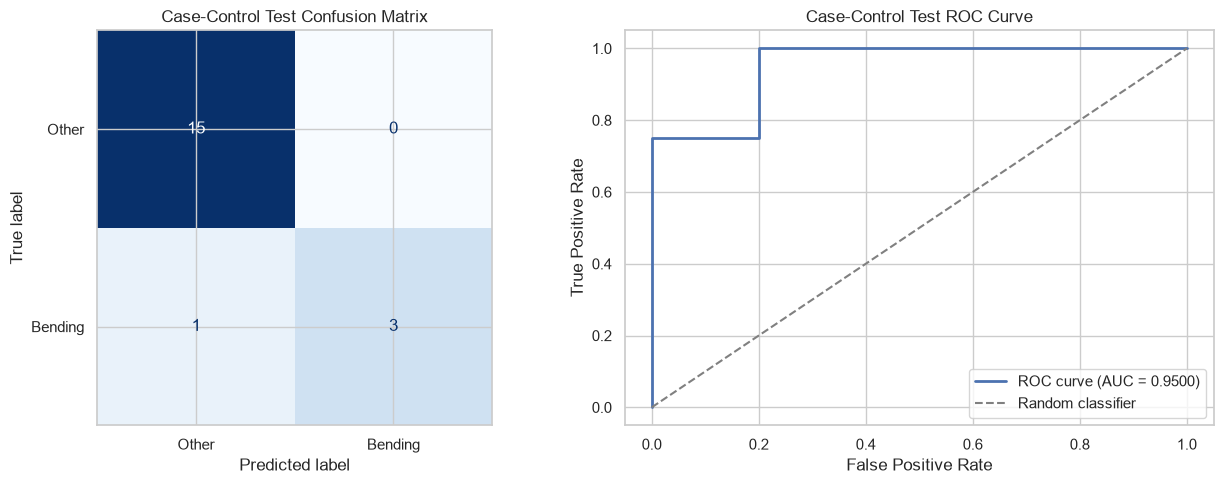

In [12]:
#find the row indices for the 2 training classes
bending_indices = y_train_best[y_train_best.eq(1)].index
other_indices = y_train_best[y_train_best.eq(0)].index

# keep all bending observations and randomly select the same number of non-bending observations to form balanced sample
sampled_other_indices = pd.Series(other_indices,).sample(n=len(bending_indices), random_state=RANDOM_STATE,).to_numpy()
case_control_indices = np.sort(np.concatenate([bending_indices.to_numpy(), sampled_other_indices,]))

X_case_control = (X_train_best.iloc[case_control_indices].reset_index(drop=True))
y_case_control = (y_train_best.iloc[case_control_indices].reset_index(drop=True))

print("Original training-class counts:")
display(y_train_best.map({0: "Other", 1: "Bending",}).value_counts())
print("Case-control training-class counts:")
display(y_case_control.map({0: "Other", 1: "Bending",}).value_counts())

# clone selected model so the original fitted model stays, cloned pipeline keeps the selected value of p
case_control_pipeline = clone(best_binary_pipeline)
case_control_pipeline.fit(X_case_control, y_case_control,)

# calc the bending proportions in the original training population & balanced case-control sample
population_prior = y_train_best.mean()
sample_prior = y_case_control.mean()

# correct the intercept for the change in prior class probabilities
intercept_adjustment = (np.log(population_prior / (1 - population_prior)) - np.log(sample_prior / (1 - sample_prior)))
case_control_classifier = (case_control_pipeline.named_steps["classifier"])
original_case_control_intercept = float(case_control_classifier.intercept_[0])
adjusted_case_control_intercept = (original_case_control_intercept + intercept_adjustment)

print("Original bending prior:", round(population_prior, 4))
print("Case-control bending prior:", round(sample_prior, 4))
print("Intercept adjustment:", round(intercept_adjustment, 4))
print("Unadjusted case-control intercept:", round(original_case_control_intercept, 4),)
print("Adjusted case-control intercept:", round(adjusted_case_control_intercept, 4),)

# convert adjusted decision scores into bending probabilities
def get_adjusted_case_control_probabilities(fitted_pipeline, feature_data, prior_adjustment,):
    sample_log_odds = fitted_pipeline.decision_function(feature_data) # decision_function returns the fitted sample-based log odds
    adjusted_log_odds = (sample_log_odds + prior_adjustment)

    # prevent numerical overflow for very large log odds.
    adjusted_log_odds = np.clip(adjusted_log_odds, -700, 700,)
    return 1 / (1 + np.exp(-adjusted_log_odds))


# eval the adjusted case-control model on the full training set
case_control_train_probabilities = (get_adjusted_case_control_probabilities(case_control_pipeline, X_train_best, intercept_adjustment,))
case_control_train_predictions = (case_control_train_probabilities >= 0.5).astype(int)
case_control_train_accuracy = accuracy_score(y_train_best, case_control_train_predictions,)
case_control_train_auc = roc_auc_score(y_train_best, case_control_train_probabilities,)

# eval the adjusted case-control model on the held-out test set
case_control_test_probabilities = (get_adjusted_case_control_probabilities(case_control_pipeline, X_test_best, intercept_adjustment,))
case_control_test_predictions = (case_control_test_probabilities >= 0.5).astype(int)
case_control_test_accuracy = accuracy_score( y_test_best, case_control_test_predictions,)
case_control_test_error = (1 - case_control_test_accuracy)
case_control_test_auc = roc_auc_score(y_test_best, case_control_test_probabilities,)
case_control_test_confusion = confusion_matrix(y_test_best, case_control_test_predictions, labels=[0, 1],)
case_control_test_confusion_table = pd.DataFrame(case_control_test_confusion, index=["Actual Other", "Actual Bending"], columns=["Predicted Other", "Predicted Bending"],)

print("\nAdjusted case-control results:")
print("Full-training accuracy:", round(case_control_train_accuracy, 4),)
print("Full-training AUC:", round(case_control_train_auc, 4),)
print("Test accuracy:", round(case_control_test_accuracy, 4),)
print("Test error:", round(case_control_test_error, 4),)
print("Test AUC:", round(case_control_test_auc, 4),)

display(case_control_test_confusion_table)

# features selected when fitting the case-control model
case_control_support = (case_control_pipeline.named_steps["rfe"].get_support())
case_control_feature_names = (X_case_control.columns[case_control_support].tolist())

# corrected intercept and the fitted slope coefficients
case_control_coefficient_table = pd.DataFrame({"Coefficient": np.concatenate([[adjusted_case_control_intercept], case_control_classifier.coef_.ravel(),])}, index=["Adjusted Intercept", *case_control_feature_names,],)

print("Case-control selected features:")
display(case_control_coefficient_table.round(6))

# ROC curve for the adjusted case-control model
case_control_fpr, case_control_tpr, _ = roc_curve(y_test_best, case_control_test_probabilities,)
figure, axes = plt.subplots(1, 2, figsize=(13, 5),)

ConfusionMatrixDisplay(confusion_matrix=case_control_test_confusion, display_labels=["Other", "Bending"],).plot(ax=axes[0], cmap="Blues", colorbar=False,)
axes[0].set_title("Case-Control Test Confusion Matrix")
axes[1].plot(case_control_fpr, case_control_tpr,
    linewidth=2,
    label=(
        "ROC curve "
        f"(AUC = {case_control_test_auc:.4f})"
    ),
)

axes[1].plot([0, 1],[0, 1],linestyle="--",color="gray",label="Random classifier",)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Case-Control Test ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

The original training set is imbalanced, with 60 non-bending instances and only 9 bending instances. Case-control sampling created a balanced training sample containing 9 instances from each class. Because this changed the bending-class prior from 0.1304 to 0.5000, I applied an intercept correction of -1.8971. The slope coefficients were not modified by this prior correction.

The adjusted case-control model correctly classified 18 of the 19 test instances. It misclassified one bending instance as non-bending,
producing a test accuracy of 0.9474, a test error of 0.0526, and an AUC of 0.9500. In comparison, the original model had a test accuracy and AUC of 1.0000. Therefore, case-control sampling didn't improve performance on this test set. This result should be interpreted with caution because the case-control model was fitted using only 18 observations, and the test set has only four bending instances.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

I use an $L_1$-penalized logistic-regression model and jointly select the number of time-series segments, $l$, and the regularization parameter using stratified five-fold cross-validation. For each value of $l \in \{1,\ldots,20\}$, the features are standardized inside a pipeline before fitting the model. Performing standardization inside the pipeline prevents information from the validation folds from leaking into model training. I search over values of $C$, where $C=1/\lambda$. Therefore, a smaller value of $C$ corresponds to stronger regularization.

In [13]:
#identical stratified folds for every value of l
l1_binary_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE,)

#broad logarithmic range of inverse regularization strengths bc C = 1 / lambda, smaller C means stronger regularization.
candidate_c_values = np.logspace(-4,4,17,)
l1_binary_best_estimators = {}
l1_binary_cv_rows = []

# Search every allowed number of time-series segments
for number_of_segments in range(1, 21):
    if number_of_segments in segmented_feature_cache:
        feature_matrix, metadata = (segmented_feature_cache[number_of_segments])
    else:
        feature_matrix, metadata = build_feature_dataset(instances, number_of_segments=number_of_segments,)
        segmented_feature_cache[number_of_segments] = (feature_matrix, metadata,)

    # use only the training instances during model selection
    training_mask = metadata["split"].eq("train")
    X_train_l1 = (feature_matrix.loc[training_mask].reset_index(drop=True))
    y_train_l1 = (metadata.loc[training_mask, "binary_label"].reset_index(drop=True))

    # standardization req because the L1 penalty is sensitive to diffs in feature scale.
    l1_binary_pipeline = Pipeline(
        steps=[
            ("scaler", StandardScaler(),),
            ("classifier", LogisticRegression(l1_ratio=1, solver="liblinear", max_iter=10000, random_state=RANDOM_STATE,),),
        ]
    )

    # select C separately for each value of l using only the cross-validation folds from the training set
    l1_binary_search = GridSearchCV(estimator=l1_binary_pipeline, param_grid={"classifier__C": candidate_c_values,}, scoring="accuracy", cv=l1_binary_cv, n_jobs=-1, refit=True, error_score="raise",)
    l1_binary_search.fit(X_train_l1, y_train_l1,)
    best_c = float(l1_binary_search.best_params_["classifier__C"])
    best_lambda = 1 / best_c
    l1_binary_best_estimators[number_of_segments] = (l1_binary_search.best_estimator_)
    l1_binary_cv_rows.append(
        {
            "l": number_of_segments,
            "C": best_c,
            "lambda": best_lambda,
            "Mean CV Accuracy": (
                l1_binary_search.best_score_
            ),
            "CV Standard Deviation": (
                l1_binary_search.cv_results_[
                    "std_test_score"
                ][l1_binary_search.best_index_]
            ),
        }
    )

    print(
        f"Completed l={number_of_segments:2d}: "
        f"best C={best_c:.6g}, "
        f"lambda={best_lambda:.6g}, "
        f"CV accuracy={l1_binary_search.best_score_:.4f}"
    )

#table containing the best C for each value of l
l1_binary_cv_results = pd.DataFrame(l1_binary_cv_rows)

# model with the highest validation accuracy, if models tie, prefer fewer segments and stronger regularization
l1_binary_cv_results = (l1_binary_cv_results.sort_values(by=["Mean CV Accuracy", "l", "C",], ascending=[False, True, True,],).reset_index(drop=True))
best_l1_binary_row = (l1_binary_cv_results.iloc[0])
best_l1_binary_l = int(best_l1_binary_row["l"])
best_l1_binary_c = float(best_l1_binary_row["C"])
best_l1_binary_lambda = float(best_l1_binary_row["lambda"])
best_l1_binary_cv_accuracy = float(best_l1_binary_row["Mean CV Accuracy"])
best_l1_binary_pipeline = (l1_binary_best_estimators[best_l1_binary_l])

print("\nBest L1-penalized binary model:")
print("Best l:", best_l1_binary_l)
print("Best C:", best_l1_binary_c)
print("Best lambda:", best_l1_binary_lambda,)
print("Best mean CV accuracy:", round(best_l1_binary_cv_accuracy, 4),)

display(l1_binary_cv_results.sort_values("l").reset_index(drop=True).round(6))

Completed l= 1: best C=0.316228, lambda=3.16228, CV accuracy=0.9714
Completed l= 2: best C=0.316228, lambda=3.16228, CV accuracy=0.9429
Completed l= 3: best C=0.316228, lambda=3.16228, CV accuracy=0.9714
Completed l= 4: best C=1, lambda=1, CV accuracy=0.9571
Completed l= 5: best C=10000, lambda=0.0001, CV accuracy=0.9429
Completed l= 6: best C=316.228, lambda=0.00316228, CV accuracy=0.9571
Completed l= 7: best C=31.6228, lambda=0.0316228, CV accuracy=0.9429
Completed l= 8: best C=3.16228, lambda=0.316228, CV accuracy=0.9275
Completed l= 9: best C=10000, lambda=0.0001, CV accuracy=0.9418
Completed l=10: best C=10, lambda=0.1, CV accuracy=0.9429
Completed l=11: best C=1, lambda=1, CV accuracy=0.9857
Completed l=12: best C=1, lambda=1, CV accuracy=0.9857
Completed l=13: best C=1, lambda=1, CV accuracy=0.9714
Completed l=14: best C=3.16228, lambda=0.316228, CV accuracy=0.9429
Completed l=15: best C=1, lambda=1, CV accuracy=0.9429
Completed l=16: best C=10, lambda=0.1, CV accuracy=0.9429
Co

,l,C,lambda,Mean CV Accuracy,CV Standard Deviation
0,1,0.316228,3.162278,0.971429,0.034993
1,2,0.316228,3.162278,0.942857,0.028571
2,3,0.316228,3.162278,0.971429,0.034993
3,4,1.000000,1.000000,0.957143,0.034993
4,5,10000.000000,0.000100,0.942857,0.069985
5,6,316.227766,0.003162,0.957143,0.057143
6,7,31.622777,0.031623,0.942857,0.053452
7,8,3.162278,0.316228,0.927473,0.045229
8,9,10000.000000,0.000100,0.941758,0.053790
9,10,10.000000,0.100000,0.942857,0.053452


The highest mean cross-validation accuracy was 0.9857. This accuracy was obtained for several values of $l$, including 11, 12, 18, 19, and 20. I selected $l=11$ because it is the smallest value among the tied models and therefore produces the least complex feature representation. For $l=11$, cross-validation selected $C=1$, which corresponds to $\lambda=1$. The selected model has a mean cross validation accuracy of 0.9857 and a cross-validation standard deviation of 0.0286.

#### ii. Comparison

I evaluate the selected $L_1$-penalized logistic-regression model on the held-out test set. I then compare its cross-validation and test performance with the unpenalized logistic-regression model that used RFE for variable selection.

Selected l: 11
Selected C: 1.0
Selected lambda: 1.0
Number of available features: 462
Number of nonzero coefficients: 8
Mean cross-validation accuracy: 0.9857
Test accuracy: 0.9474
Test error: 0.0526
Test AUC: 1.0

L1 test confusion matrix:


,Predicted Other,Predicted Bending
Actual Other,15,0
Actual Bending,1,3


Nonzero L1 coefficients:


,Feature,Coefficient
0,series5_segment2_1st_quart,1.303821
1,series1_segment6_max,-0.784633
2,series5_segment10_min,0.724139
3,series5_segment2_median,0.586268
4,series4_segment8_median,-0.314168
5,series5_segment1_max,0.253443
6,series6_segment9_std,-0.148786
7,series6_segment10_max,-0.028110


Binary-model comparison:


,Model,Selected l,Selected Features,Mean CV Accuracy,Test Accuracy,Test Error,Test AUC
0,Unpenalized Logistic Regression with RFE,1,3,0.9857,1.0000,0.0000,1.0
1,L1-Penalized Logistic Regression,11,8,0.9857,0.9474,0.0526,1.0


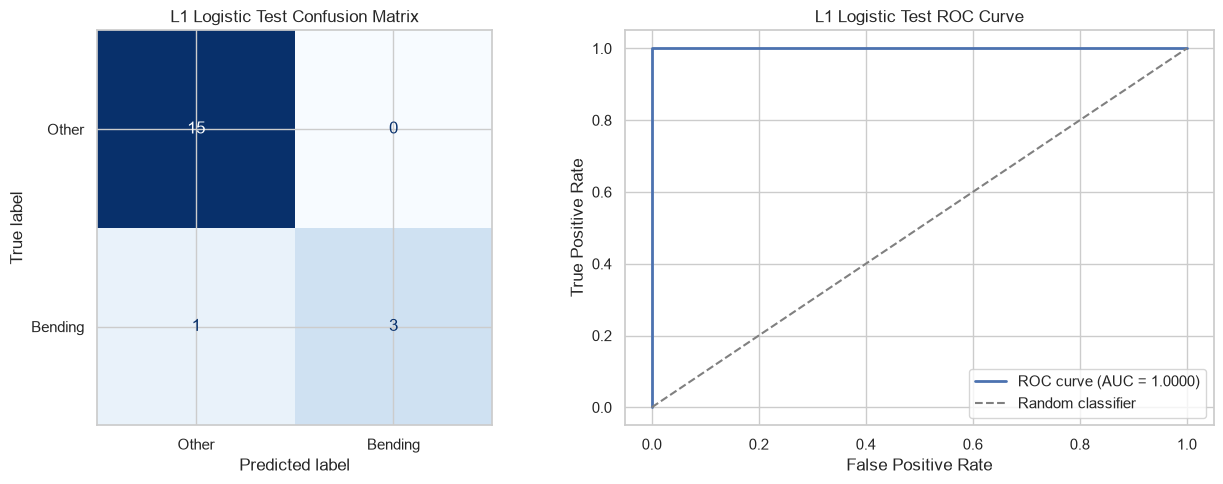

In [14]:
# get the feature matrix corresponding to the selected value of l
l1_best_feature_matrix, l1_best_metadata = (segmented_feature_cache[best_l1_binary_l])

# separate the training and test instances
l1_training_mask = (l1_best_metadata["split"].eq("train"))
l1_test_mask = (l1_best_metadata["split"].eq("test"))
X_l1_train = (l1_best_feature_matrix.loc[l1_training_mask].reset_index(drop=True))
y_l1_train = (l1_best_metadata.loc[l1_training_mask, "binary_label",].reset_index(drop=True))
X_l1_test = (l1_best_feature_matrix.loc[l1_test_mask].reset_index(drop=True))
y_l1_test = (l1_best_metadata.loc[l1_test_mask, "binary_label",].reset_index(drop=True))

# gen preds and bending probs using the model selected from training data
l1_test_predictions = (best_l1_binary_pipeline.predict(X_l1_test))
l1_test_probabilities = (best_l1_binary_pipeline.predict_proba(X_l1_test)[:, 1])

l1_test_accuracy = accuracy_score(y_l1_test, l1_test_predictions,)
l1_test_error = (1 - l1_test_accuracy)
l1_test_auc = roc_auc_score(y_l1_test, l1_test_probabilities,)
l1_test_confusion = confusion_matrix(y_l1_test, l1_test_predictions, labels=[0, 1],)
l1_test_confusion_table = pd.DataFrame(l1_test_confusion, index=["Actual Other", "Actual Bending"], columns=["Predicted Other", "Predicted Bending"],)

# id the features that have nonzero L1 coefficients
l1_classifier = (best_l1_binary_pipeline.named_steps["classifier"])
l1_coefficients = (l1_classifier.coef_.ravel())
nonzero_mask = (np.abs(l1_coefficients) > 1e-8)
nonzero_feature_names = (X_l1_train.columns[nonzero_mask].tolist())
nonzero_coefficients = (l1_coefficients[nonzero_mask])

l1_coefficient_table = pd.DataFrame({"Feature": nonzero_feature_names, "Coefficient": nonzero_coefficients,}).sort_values(by="Coefficient", key=np.abs, ascending=False,).reset_index(drop=True)

print("Selected l:", best_l1_binary_l)
print("Selected C:", best_l1_binary_c)
print("Selected lambda:", best_l1_binary_lambda)
print("Number of available features:", X_l1_train.shape[1],)
print("Number of nonzero coefficients:", nonzero_mask.sum(),)
print("Mean cross-validation accuracy:", round(best_l1_binary_cv_accuracy, 4),)
print("Test accuracy:", round(l1_test_accuracy, 4),)
print("Test error:", round(l1_test_error, 4),)
print("Test AUC:", round(l1_test_auc, 4),)

print("\nL1 test confusion matrix:")
display(l1_test_confusion_table)

print("Nonzero L1 coefficients:")
display(l1_coefficient_table.round(6))

# compare the l1 model with the rfe model
binary_model_comparison = pd.DataFrame(
    {
        "Model": ["Unpenalized Logistic Regression with RFE", "L1-Penalized Logistic Regression",],
        "Selected l": [best_binary_l, best_l1_binary_l,],
        "Selected Features": [best_binary_p, int(nonzero_mask.sum()),],
        "Mean CV Accuracy": [best_binary_cv_accuracy, best_l1_binary_cv_accuracy,],
        "Test Accuracy": [test_accuracy, l1_test_accuracy,],
        "Test Error": [1 - test_accuracy, l1_test_error,],
        "Test AUC": [test_auc, l1_test_auc,],
    }
)

print("Binary-model comparison:")
display(binary_model_comparison.round(4))

# calc the roc curve for l1
l1_test_fpr, l1_test_tpr, _ = roc_curve(y_l1_test, l1_test_probabilities,)
figure, axes = plt.subplots(1, 2, figsize=(13, 5),)
ConfusionMatrixDisplay(confusion_matrix=l1_test_confusion, display_labels=["Other", "Bending"],).plot(ax=axes[0], cmap="Blues", colorbar=False,)

axes[0].set_title("L1 Logistic Test Confusion Matrix")
axes[1].plot(l1_test_fpr, l1_test_tpr, linewidth=2, label=f"ROC curve (AUC = {l1_test_auc:.4f})",)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier",)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("L1 Logistic Test ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

Both models resulted in the same mean cross-validation accuracy of 0.9857, but their selected representations and test results were different. The unpenalized model with RFE selected $l=1$ and three features. It correctly classified all 19 test instances, giving a test error of 0.0000 and an AUC of 1.0000. The $L_1$-penalized model selected $l=11$ and retained 8 nonzero coefficients from 462 available features. It misclassified one bending instance, giving a test error of 0.0526 and an AUC of 1.0000. The $L_1$ model's AUC can equal 1.0000 despite making one classification error because AUC measures the ranking of predicted probabilities over all possible thresholds, while the confusion matrix uses a fixed threshold of 0.5. For this dataset, the RFE model produced the lower test error and used fewer selected features.

The $L_1$-penalized model was easier to implement because coefficient shrinkage and feature selection occurred automatically during model fitting. The RFE method required an additional feature-selection step inside every cross-validation fold. It also encountered complete separation, which prevented reliable estimation of the ordinary p-values.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

I classify the observations into their seven original activity classes using $L_1$-penalized multinomial logistic regression. I jointly select the number of time-series segments, $l$, and the inverse regularization parameter, $C=1/\lambda$. The smallest training class contains only four observations. Therefore, I use four-fold stratified cross-validation rather than five-fold cross-validation so that every validation fold can contain an observation from each activity class. Standardization is performed inside the model pipeline to prevent cross-validation leakage.

In [15]:
#activity labels and verify the multiclass training counts
base_feature_matrix, base_metadata = (segmented_feature_cache[1])
base_training_mask = (base_metadata["split"].eq("train"))
multiclass_training_counts = (base_metadata.loc[base_training_mask, "activity",].value_counts().sort_index())

print("Multiclass training counts:")
display(multiclass_training_counts)

#no more folds than the number of observations in the smallest training class
multiclass_number_of_folds = min(5,int(multiclass_training_counts.min()),)
print("Number of stratified folds:", multiclass_number_of_folds,)
multiclass_cv = StratifiedKFold(n_splits=multiclass_number_of_folds, shuffle=True, random_state=RANDOM_STATE,)

# search same logarithmic grid used for binary L1 regression, C is the inverse of lambda
multiclass_candidate_c_values = np.logspace(-4, 4, 17,)
multiclass_best_estimators = {}
multiclass_cv_rows = []

#search the segmentation level and regularization strength
for number_of_segments in range(1, 21):
    #segmented feature matrix from the cache
    feature_matrix, metadata = (segmented_feature_cache[number_of_segments])
    training_mask = (metadata["split"].eq("train"))
    X_multiclass_train = (feature_matrix.loc[training_mask].reset_index(drop=True))
    y_multiclass_train = (metadata.loc[training_mask, "activity",].reset_index(drop=True))

    #saga solver supports L1-penalized multinomial regression
    multiclass_pipeline = Pipeline(steps=[("scaler",StandardScaler(),), ("classifier", LogisticRegression(l1_ratio=1, solver="saga", max_iter=20000, tol=1e-3, random_state=RANDOM_STATE,),),])
    multiclass_search = GridSearchCV(estimator=multiclass_pipeline, param_grid={"classifier__C": (multiclass_candidate_c_values),}, scoring="accuracy", cv=multiclass_cv, n_jobs=-1, refit=True, error_score="raise",)
    multiclass_search.fit(X_multiclass_train, y_multiclass_train,)
    best_multiclass_c_for_l = float(multiclass_search.best_params_["classifier__C"])
    best_multiclass_lambda_for_l = (1 / best_multiclass_c_for_l)

    multiclass_best_estimators[number_of_segments] = multiclass_search.best_estimator_
    multiclass_cv_rows.append(
        {
            "l": number_of_segments,
            "C": best_multiclass_c_for_l,
            "lambda": (
                best_multiclass_lambda_for_l
            ),
            "Mean CV Accuracy": (
                multiclass_search.best_score_
            ),
            "CV Standard Deviation": (
                multiclass_search.cv_results_[
                    "std_test_score"
                ][multiclass_search.best_index_]
            ),
        }
    )

    print(
        f"Completed l={number_of_segments:2d}: "
        f"best C={best_multiclass_c_for_l:.6g}, "
        f"lambda={best_multiclass_lambda_for_l:.6g}, "
        f"CV accuracy={multiclass_search.best_score_:.4f}"
    )

#best regularization result for every value of l
multiclass_cv_results = pd.DataFrame(multiclass_cv_rows)

#highest validation accuracy. if vals tie, choose fewer segments and then the stronger L1 penalty
multiclass_cv_results = (multiclass_cv_results.sort_values(by=["Mean CV Accuracy", "l", "C",], ascending=[False, True, True,],).reset_index(drop=True))
best_multiclass_row = (multiclass_cv_results.iloc[0])
best_multiclass_l = int(best_multiclass_row["l"])
best_multiclass_c = float(best_multiclass_row["C"])
best_multiclass_lambda = float(best_multiclass_row["lambda"])
best_multiclass_cv_accuracy = float(best_multiclass_row["Mean CV Accuracy"])
best_multiclass_pipeline = (multiclass_best_estimators[best_multiclass_l])
print("\nBest L1-penalized multinomial model:")
print("Best l:", best_multiclass_l)
print("Best C:", best_multiclass_c)
print("Best lambda:",best_multiclass_lambda,)
print("Best mean CV accuracy:", round(best_multiclass_cv_accuracy, 4),)
display(multiclass_cv_results.sort_values("l").reset_index(drop=True).round(6))

Multiclass training counts:


activity
bending1     5
bending2     4
cycling     12
lying       12
sitting     12
standing    12
walking     12
Name: count, dtype: int64

Number of stratified folds: 4
Completed l= 1: best C=3.16228, lambda=0.316228, CV accuracy=0.9134
Completed l= 2: best C=316.228, lambda=0.00316228, CV accuracy=0.9273
Completed l= 3: best C=100, lambda=0.01, CV accuracy=0.8979
Completed l= 4: best C=100, lambda=0.01, CV accuracy=0.8979
Completed l= 5: best C=3.16228, lambda=0.316228, CV accuracy=0.8685
Completed l= 6: best C=316.228, lambda=0.00316228, CV accuracy=0.8685
Completed l= 7: best C=3.16228, lambda=0.316228, CV accuracy=0.8391
Completed l= 8: best C=31.6228, lambda=0.0316228, CV accuracy=0.8243
Completed l= 9: best C=31.6228, lambda=0.0316228, CV accuracy=0.8415
Completed l=10: best C=31.6228, lambda=0.0316228, CV accuracy=0.8391
Completed l=11: best C=316.228, lambda=0.00316228, CV accuracy=0.8113
Completed l=12: best C=31.6228, lambda=0.0316228, CV accuracy=0.8546
Completed l=13: best C=100, lambda=0.01, CV accuracy=0.8399
Completed l=14: best C=1, lambda=1, CV accuracy=0.8538
Completed l=15: best C=100, lambda=0.01, CV a

,l,C,lambda,Mean CV Accuracy,CV Standard Deviation
0,1,3.162278,0.316228,0.913399,0.027874
1,2,316.227766,0.003162,0.927288,0.025977
2,3,100.000000,0.010000,0.897876,0.026886
3,4,100.000000,0.010000,0.897876,0.049528
4,5,3.162278,0.316228,0.868464,0.050010
5,6,316.227766,0.003162,0.868464,0.050010
6,7,3.162278,0.316228,0.839052,0.065416
7,8,31.622777,0.031623,0.824346,0.073379
8,9,31.622777,0.031623,0.841503,0.043936
9,10,31.622777,0.031623,0.839052,0.065416


The smallest activity class contains four training instances, so I used four-fold stratified cross-validation. The best multinomial model used $l=2$ and $C=316.2278$, corresponding to $\lambda \approx 0.003162$. This model obtained a mean cross-validation accuracy of 0.9273 with a cross-validation standard deviation of approximately 0.0260. The relatively large value of $C$ indicates that cross-validation preferred a comparatively weak $L_1$ penalty for this feature representation.

##### Multiclass Test-Set Evaluation

I evaluate the selected multinomial logistic-regression model on the held-out test set. For ROC analysis, I treat each activity as the
positive class in turn and combine the remaining activities into the negative class. This produces a one-versus-rest ROC curve and AUC for each of the seven activities.

Selected l: 2
Selected C: 316.227766
Selected lambda: 0.003162
Mean CV accuracy: 0.9273
Test accuracy: 0.8421
Test error: 0.1579
Macro one-vs-rest test AUC: 0.9839
Total nonzero class-feature coefficients: 578

Multiclass test confusion matrix:


,Predicted bending1,Predicted bending2,Predicted cycling,Predicted lying,Predicted sitting,Predicted standing,Predicted walking
Actual bending1,2,0,0,0,0,0,0
Actual bending2,0,1,0,0,1,0,0
Actual cycling,0,0,3,0,0,0,0
Actual lying,0,0,0,3,0,0,0
Actual sitting,1,0,0,0,1,1,0
Actual standing,0,0,0,0,0,3,0
Actual walking,0,0,0,0,0,0,3


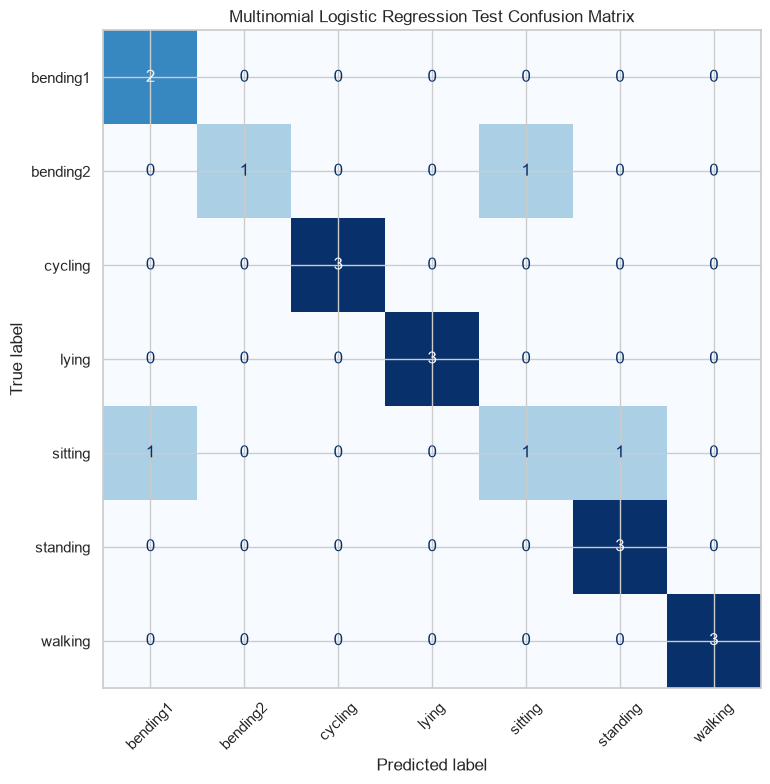

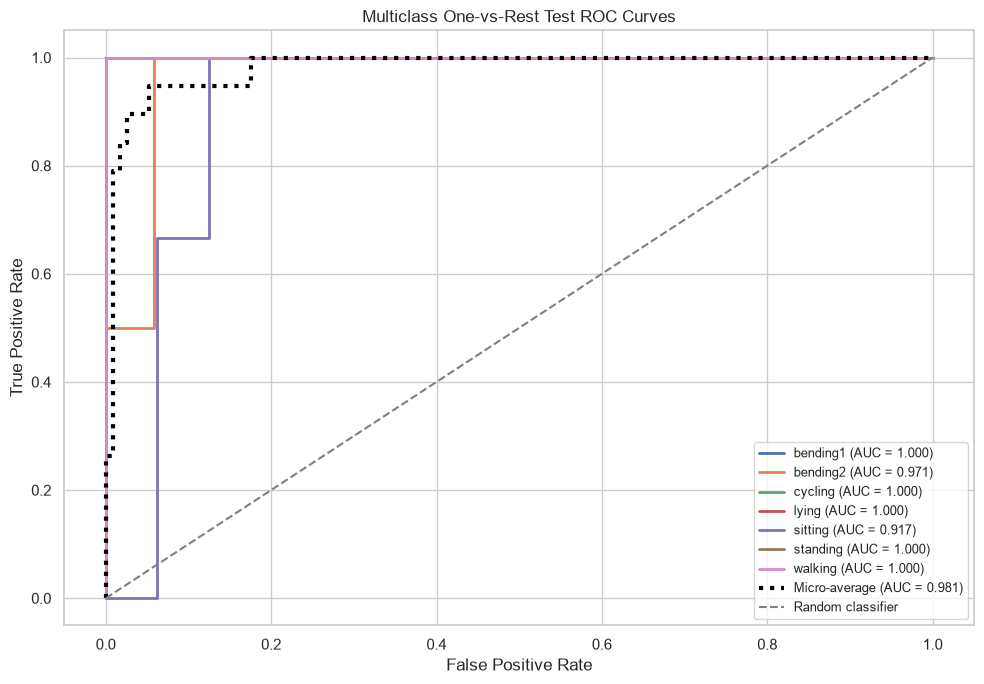

,Activity,One-vs-Rest AUC
0,bending1,1.0000
1,bending2,0.9706
2,cycling,1.0000
3,lying,1.0000
4,sitting,0.9167
5,standing,1.0000
6,walking,1.0000


Micro-average test AUC: 0.9811
Macro-average test AUC: 0.9839


In [16]:
# retrieve the feature matrix for the selected segmentation level
multiclass_feature_matrix, multiclass_metadata = (segmented_feature_cache[best_multiclass_l])
multiclass_training_mask = (multiclass_metadata["split"].eq("train"))
multiclass_test_mask = (multiclass_metadata["split"].eq("test"))
X_multiclass_train = (multiclass_feature_matrix.loc[multiclass_training_mask].reset_index(drop=True))
y_multiclass_train = (multiclass_metadata.loc[multiclass_training_mask, "activity",].reset_index(drop=True))
X_multiclass_test = (multiclass_feature_matrix.loc[multiclass_test_mask].reset_index(drop=True))
y_multiclass_test = (multiclass_metadata.loc[multiclass_test_mask, "activity",].reset_index(drop=True))

# predicted classes and class probabilities for the test set
multiclass_test_predictions = (best_multiclass_pipeline.predict(X_multiclass_test))
multiclass_test_probabilities = (best_multiclass_pipeline.predict_proba(X_multiclass_test))
multiclass_classifier = (best_multiclass_pipeline.named_steps["classifier"])
multiclass_class_labels = (multiclass_classifier.classes_)

# test accuracy, error, and the macro one-versus-rest AUC
multiclass_test_accuracy = accuracy_score(y_multiclass_test,multiclass_test_predictions,)
multiclass_test_error = (1 - multiclass_test_accuracy)
multiclass_macro_auc = roc_auc_score(y_multiclass_test, multiclass_test_probabilities, labels=multiclass_class_labels, multi_class="ovr", average="macro",)

#multiclass confusion matrix using a fixed class order.
multiclass_test_confusion = confusion_matrix(y_multiclass_test, multiclass_test_predictions, labels=multiclass_class_labels,)
multiclass_test_confusion_table = pd.DataFrame(multiclass_test_confusion,
    index=[f"Actual {label}" for label in multiclass_class_labels],
    columns=[f"Predicted {label}" for label in multiclass_class_labels],
)

#num of nonzero coefficients across all class models
multiclass_coefficients = (multiclass_classifier.coef_)
multiclass_nonzero_coefficient_count = int(np.sum(np.abs(multiclass_coefficients) > 1e-8))

print("Selected l:", best_multiclass_l)
print("Selected C:", round(best_multiclass_c, 6))
print("Selected lambda:", round(best_multiclass_lambda, 6),)
print("Mean CV accuracy:", round(best_multiclass_cv_accuracy, 4),)
print("Test accuracy:", round(multiclass_test_accuracy, 4),)
print("Test error:", round(multiclass_test_error, 4),)
print("Macro one-vs-rest test AUC:", round(multiclass_macro_auc, 4),)
print("Total nonzero class-feature coefficients:", multiclass_nonzero_coefficient_count,)
print("\nMulticlass test confusion matrix:")
display(multiclass_test_confusion_table)

#seven-class test confusion matrix
figure, axis = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(confusion_matrix=multiclass_test_confusion, display_labels=multiclass_class_labels,).plot(ax=axis, cmap="Blues", colorbar=False, xticks_rotation=45,)
axis.set_title("Multinomial Logistic Regression Test Confusion Matrix")
plt.tight_layout()
plt.show()

# true activity labels to one-versus-rest indicator cols
multiclass_test_binary = label_binarize(y_multiclass_test, classes=multiclass_class_labels,)
multiclass_roc_results = {}
figure, axis = plt.subplots(figsize=(10, 7))

for class_index, class_label in enumerate(multiclass_class_labels):
    class_false_positive_rate, class_true_positive_rate, _ = (roc_curve(multiclass_test_binary[:, class_index], multiclass_test_probabilities[:, class_index],))
    class_auc = roc_auc_score(multiclass_test_binary[:, class_index], multiclass_test_probabilities[:, class_index],)
    multiclass_roc_results[class_label] = {"AUC": class_auc,}
    axis.plot(class_false_positive_rate, class_true_positive_rate, linewidth=2,
        label=(
            f"{class_label} "
            f"(AUC = {class_auc:.3f})"
        ),
    )

# micro-avg ROC curve over all class decisions
micro_false_positive_rate, micro_true_positive_rate, _ = (roc_curve(multiclass_test_binary.ravel(), multiclass_test_probabilities.ravel(),))
micro_auc = roc_auc_score(multiclass_test_binary.ravel(), multiclass_test_probabilities.ravel(),)
axis.plot(micro_false_positive_rate, micro_true_positive_rate, color="black", linestyle=":",linewidth=3, label=f"Micro-average (AUC = {micro_auc:.3f})",)
axis.plot([0, 1], [0, 1],linestyle="--", color="gray", label="Random classifier",)
axis.set_xlabel("False Positive Rate")
axis.set_ylabel("True Positive Rate")
axis.set_title("Multiclass One-vs-Rest Test ROC Curves")
axis.legend(loc="lower right", fontsize=9,)
plt.tight_layout()
plt.show()

#class-specific AUC values in table
multiclass_auc_table = pd.DataFrame([{"Activity": class_label, "One-vs-Rest AUC": (multiclass_roc_results[class_label]["AUC"]),} for class_label in multiclass_class_labels])
display(multiclass_auc_table.round(4))
print("Micro-average test AUC:", round(micro_auc, 4),)
print("Macro-average test AUC:", round(multiclass_macro_auc, 4),)

The selected multinomial logistic-regression model got a test accuracy of 0.8421 and a test error of 0.1579, correctly classifying 16 of the 19 test instances. It misclassified one `bending2` instance as `sitting` and misclassified two `sitting` instances as `bending1` and `standing`. The model got a micro-average one-versus-rest AUC of 0.9811 and a macro-average AUC of 0.9839. Five activities had an AUC of 1.0000, while `bending2` had an AUC of 0.9706 and `sitting` had the lowest AUC at 0.9167. Thus, most classes were ranked very well, even though the highest-probability classification rule produced three errors. The model retained 578 of the 588 possible class-feature coefficients. This limited sparsity is consistent with the small selected penalty, $\lambda \approx 0.003162$.

#### ii. Naive Bayes

I repeat the multiclass analysis using Gaussian Naive Bayes and Multinomial Naive Bayes. For each classifier, I use four-fold stratified cross-validation to select the number of time-series segments, $l \in \{1,\ldots,20\}$. Gaussian Naive Bayes models each feature using a class-specific Gaussian distribution. Multinomial Naive Bayes requires nonnegative feature values, so I check that all extracted features are nonnegative before fitting that model.

In [17]:
naive_bayes_cv_rows = []

# eval both nb classifiers for every allowed value of l
for number_of_segments in range(1, 21):
    feature_matrix, metadata = (segmented_feature_cache[number_of_segments])
    training_mask = (metadata["split"].eq("train"))
    X_nb_train = (feature_matrix.loc[training_mask].reset_index(drop=True))
    y_nb_train = (metadata.loc[training_mask, "activity",].reset_index(drop=True))

    minimum_feature_value = float(X_nb_train.min().min())
    if minimum_feature_value < 0:
        raise ValueError(
            "Multinomial Naive Bayes requires nonnegative features, "
            f"but l={number_of_segments} contains a minimum value of "
            f"{minimum_feature_value}."
        )

    # GNB models each feature with a gaussian dens
    gaussian_nb_model = GaussianNB()
    gaussian_cv_scores = cross_val_score(gaussian_nb_model, X_nb_train, y_nb_train, scoring="accuracy", cv=multiclass_cv, n_jobs=-1,)

    # Mnb is applied to the original nonnegative feature vals, default Laplace smoothing parameter used
    multinomial_nb_model = MultinomialNB(alpha=1.0,)
    multinomial_cv_scores = cross_val_score(multinomial_nb_model, X_nb_train, y_nb_train, scoring="accuracy", cv=multiclass_cv, n_jobs=-1,)
    naive_bayes_cv_rows.extend([{"Model": "Gaussian Naive Bayes", "l": number_of_segments, "Mean CV Accuracy": (gaussian_cv_scores.mean()), "CV Standard Deviation": (gaussian_cv_scores.std()),}, {"Model": "Multinomial Naive Bayes", "l": number_of_segments, "Mean CV Accuracy": (multinomial_cv_scores.mean()), "CV Standard Deviation": (multinomial_cv_scores.std()),},])
    print(
        f"Completed l={number_of_segments:2d}: "
        f"Gaussian accuracy={gaussian_cv_scores.mean():.4f}, "
        f"Multinomial accuracy={multinomial_cv_scores.mean():.4f}"
    )

# all cross-validation results in one table
naive_bayes_cv_results = pd.DataFrame(naive_bayes_cv_rows)

#best l separately for each Naive Bayes classifier. if accuracies tie, sorting by l = simpler rep
gaussian_nb_results = (naive_bayes_cv_results.loc[naive_bayes_cv_results["Model"].eq("Gaussian Naive Bayes")].sort_values(by=["Mean CV Accuracy", "l",], ascending=[False, True,],).reset_index(drop=True))
multinomial_nb_results = (naive_bayes_cv_results.loc[naive_bayes_cv_results["Model"].eq("Multinomial Naive Bayes")].sort_values(by=["Mean CV Accuracy", "l",], ascending=[False, True,],).reset_index(drop=True))

best_gaussian_nb_row = (gaussian_nb_results.iloc[0])
best_multinomial_nb_row = (multinomial_nb_results.iloc[0])
best_gaussian_nb_l = int(best_gaussian_nb_row["l"])
best_gaussian_nb_cv_accuracy = float(best_gaussian_nb_row["Mean CV Accuracy"])
best_multinomial_nb_l = int(best_multinomial_nb_row["l"])
best_multinomial_nb_cv_accuracy = float(best_multinomial_nb_row["Mean CV Accuracy"])
print("\nBest Gaussian Naive Bayes model:")
print("Best l:", best_gaussian_nb_l)
print("Best mean CV accuracy:", round(best_gaussian_nb_cv_accuracy, 4),)
print("\nBest Multinomial Naive Bayes model:")
print("Best l:", best_multinomial_nb_l)
print("Best mean CV accuracy:", round(best_multinomial_nb_cv_accuracy, 4),)

#results for both classifiers side by side by l
naive_bayes_cv_pivot = (naive_bayes_cv_results.pivot(index="l", columns="Model", values="Mean CV Accuracy",).reset_index())
display(naive_bayes_cv_pivot.round(4))

Completed l= 1: Gaussian accuracy=0.8701, Multinomial accuracy=0.8423
Completed l= 2: Gaussian accuracy=0.8562, Multinomial accuracy=0.8129
Completed l= 3: Gaussian accuracy=0.7533, Multinomial accuracy=0.7982
Completed l= 4: Gaussian accuracy=0.6969, Multinomial accuracy=0.7974
Completed l= 5: Gaussian accuracy=0.7402, Multinomial accuracy=0.8399
Completed l= 6: Gaussian accuracy=0.6806, Multinomial accuracy=0.8105
Completed l= 7: Gaussian accuracy=0.6806, Multinomial accuracy=0.8260
Completed l= 8: Gaussian accuracy=0.6217, Multinomial accuracy=0.8243
Completed l= 9: Gaussian accuracy=0.6234, Multinomial accuracy=0.8113
Completed l=10: Gaussian accuracy=0.6806, Multinomial accuracy=0.8252
Completed l=11: Gaussian accuracy=0.6381, Multinomial accuracy=0.8399
Completed l=12: Gaussian accuracy=0.6234, Multinomial accuracy=0.8252
Completed l=13: Gaussian accuracy=0.6242, Multinomial accuracy=0.8252
Completed l=14: Gaussian accuracy=0.5801, Multinomial accuracy=0.8113
Completed l=15: Gaus

Model,l,Gaussian Naive Bayes,Multinomial Naive Bayes
0,1,0.8701,0.8423
1,2,0.8562,0.8129
2,3,0.7533,0.7982
3,4,0.6969,0.7974
4,5,0.7402,0.8399
5,6,0.6806,0.8105
6,7,0.6806,0.8260
7,8,0.6217,0.8243
8,9,0.6234,0.8113
9,10,0.6806,0.8252


Cross-validation selected $l=1$ for both Naive Bayes classifiers. Gaussian Naive Bayes achieved a mean cross-validation accuracy of 0.8701, while Multinomial Naive Bayes achieved a mean accuracy of 0.8423. Gaussian Naive Bayes performed better in cross-validation. For both models, dividing the series into additional segments didn't improve the best validation result. The decline in Gaussian Naive Bayes accuracy for larger values of $l$ may result from estimating many class-specific feature distributions from only 69 training instances.

##### Naive Bayes Test-Set Evaluation

I fit each Naive Bayes classifier using its cross-validation-selected value of $l$ and the complete training set. I then evaluate each model on the held-out test set using test error, a confusion matrix, and one-versus-rest ROC curves and AUC values.

,Model,Selected l,Mean CV Accuracy,Test Accuracy,Test Error,Micro-Average AUC,Macro-Average AUC
0,Gaussian Naive Bayes,1,0.8701,0.8947,0.1053,0.9596,0.9643
1,Multinomial Naive Bayes,1,0.8423,0.8947,0.1053,0.9926,0.9851


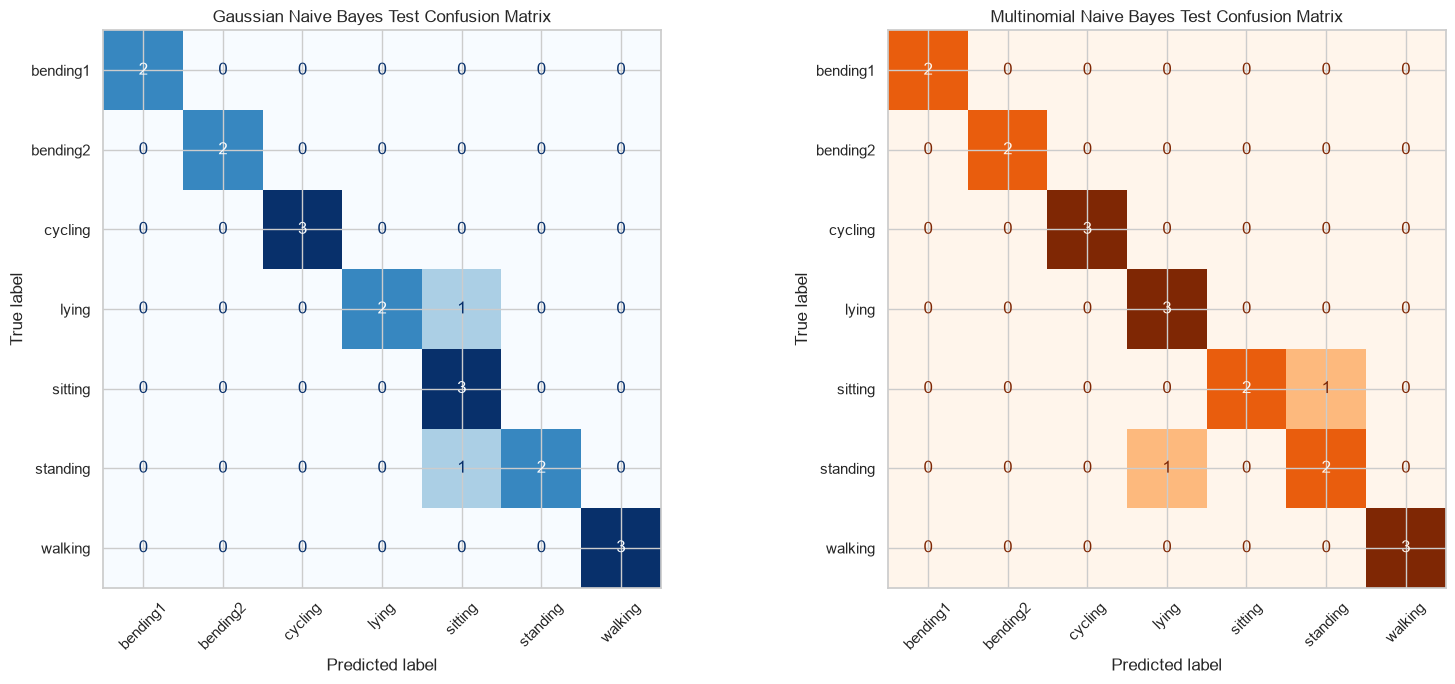

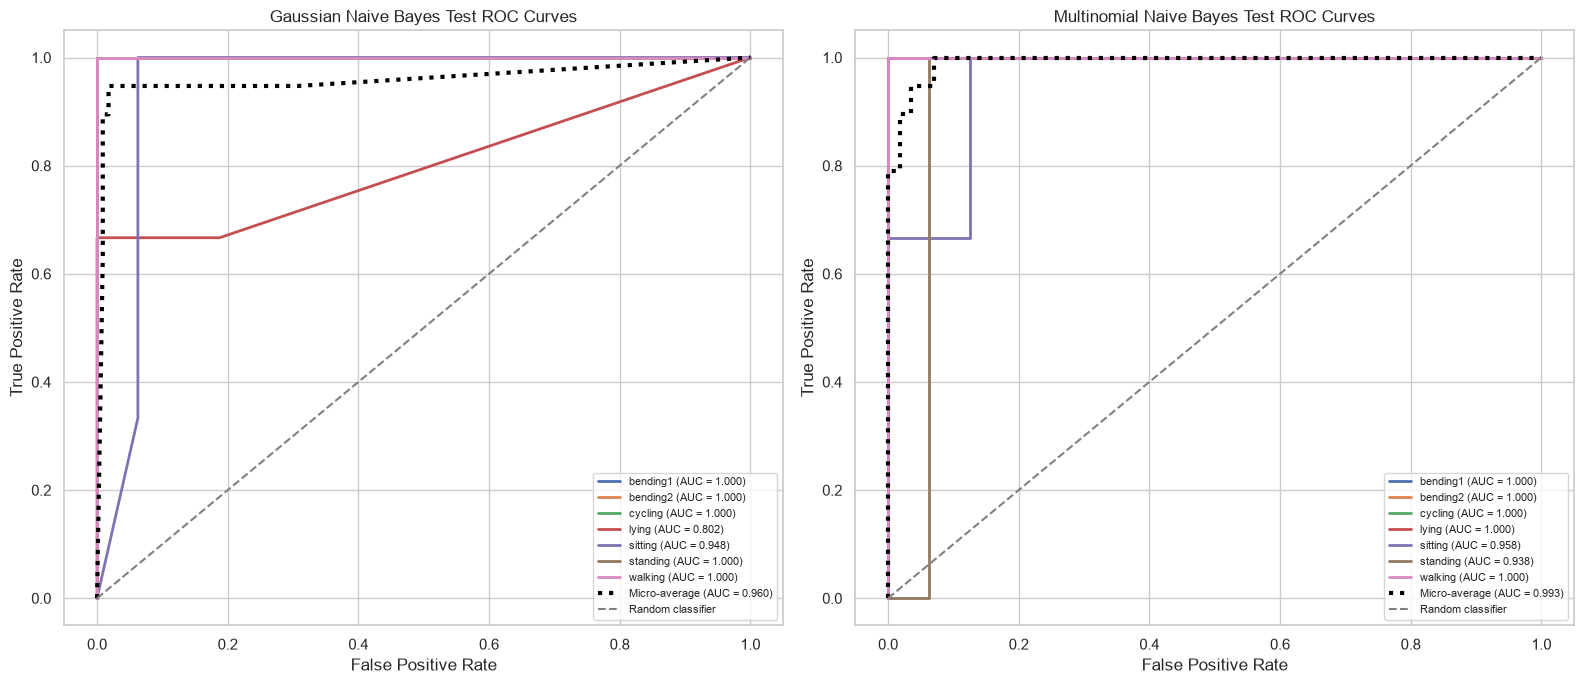

,Activity,Gaussian NB AUC,Multinomial NB AUC
0,bending1,1.0000,1.0000
1,bending2,1.0000,1.0000
2,cycling,1.0000,1.0000
3,lying,0.8021,1.0000
4,sitting,0.9479,0.9583
5,standing,1.0000,0.9375
6,walking,1.0000,1.0000


In [18]:
# reusable func for multiclass classifiers
def evaluate_multiclass_model(fitted_model, X_test, y_test,):
    #calc predictions, confusion matrix, & multiclass AUCs
    predictions = fitted_model.predict(X_test)
    probabilities = fitted_model.predict_proba(X_test)
    class_labels = fitted_model.classes_
    accuracy = accuracy_score(y_test, predictions,)
    error = 1 - accuracy
    confusion = confusion_matrix(y_test, predictions, labels=class_labels,)

    # true labels -> one-versus-rest binary columns
    binary_labels = label_binarize(y_test, classes=class_labels,)
    class_auc_values = {}

    for class_index, class_label in enumerate(class_labels):
        class_auc_values[class_label] = (roc_auc_score(binary_labels[:, class_index], probabilities[:, class_index],))

    macro_auc = roc_auc_score(y_test, probabilities, labels=class_labels, multi_class="ovr", average="macro",)
    micro_auc = roc_auc_score(binary_labels.ravel(), probabilities.ravel(),)

    return {
        "predictions": predictions,
        "probabilities": probabilities,
        "class_labels": class_labels,
        "binary_labels": binary_labels,
        "accuracy": accuracy,
        "error": error,
        "confusion": confusion,
        "class_auc_values": class_auc_values,
        "macro_auc": macro_auc,
        "micro_auc": micro_auc,
    }


# l=1 data selected for gnb
gaussian_feature_matrix, gaussian_metadata = (segmented_feature_cache[best_gaussian_nb_l])
gaussian_training_mask = (gaussian_metadata["split"].eq("train"))
gaussian_test_mask = (gaussian_metadata["split"].eq("test"))

X_gaussian_train = (gaussian_feature_matrix.loc[gaussian_training_mask].reset_index(drop=True))
y_gaussian_train = (gaussian_metadata.loc[gaussian_training_mask, "activity",].reset_index(drop=True))

X_gaussian_test = (gaussian_feature_matrix.loc[gaussian_test_mask].reset_index(drop=True))
y_gaussian_test = (gaussian_metadata.loc[gaussian_test_mask, "activity",].reset_index(drop=True))

# fit gnb on the complete training set
best_gaussian_nb_model = GaussianNB()
best_gaussian_nb_model.fit(X_gaussian_train, y_gaussian_train,)
gaussian_test_results = evaluate_multiclass_model(best_gaussian_nb_model, X_gaussian_test, y_gaussian_test,)

# prep data selected for mnb
multinomial_feature_matrix, multinomial_metadata = (segmented_feature_cache[best_multinomial_nb_l])
multinomial_training_mask = (multinomial_metadata["split"].eq("train"))
multinomial_test_mask = (multinomial_metadata["split"].eq("test"))

X_multinomial_train = (multinomial_feature_matrix.loc[multinomial_training_mask].reset_index(drop=True))
y_multinomial_train = (multinomial_metadata.loc[multinomial_training_mask, "activity",].reset_index(drop=True))

X_multinomial_test = (multinomial_feature_matrix.loc[multinomial_test_mask].reset_index(drop=True))
y_multinomial_test = (multinomial_metadata.loc[multinomial_test_mask, "activity",].reset_index(drop=True))

# fit mnb on the complete training set
best_multinomial_nb_model = MultinomialNB(alpha=1.0,)
best_multinomial_nb_model.fit(X_multinomial_train, y_multinomial_train,)
multinomial_test_results = evaluate_multiclass_model(best_multinomial_nb_model, X_multinomial_test, y_multinomial_test,)

#numerical comp of two Naive Bayes models
naive_bayes_test_comparison = pd.DataFrame(
    {
        "Model": ["Gaussian Naive Bayes", "Multinomial Naive Bayes",],
        "Selected l": [best_gaussian_nb_l, best_multinomial_nb_l,],
        "Mean CV Accuracy": [best_gaussian_nb_cv_accuracy, best_multinomial_nb_cv_accuracy,],
        "Test Accuracy": [gaussian_test_results["accuracy"], multinomial_test_results["accuracy"],],
        "Test Error": [gaussian_test_results["error"], multinomial_test_results["error"],],
        "Micro-Average AUC": [gaussian_test_results["micro_auc"], multinomial_test_results["micro_auc"],],
        "Macro-Average AUC": [gaussian_test_results["macro_auc"], multinomial_test_results["macro_auc"],],
    }
)

display(naive_bayes_test_comparison.round(4))

#test confusion matrices
figure, axes = plt.subplots(1, 2, figsize=(16, 7),)
ConfusionMatrixDisplay(confusion_matrix=gaussian_test_results["confusion"], display_labels=gaussian_test_results["class_labels"],).plot(ax=axes[0], cmap="Blues", colorbar=False, xticks_rotation=45,)
axes[0].set_title("Gaussian Naive Bayes Test Confusion Matrix")
ConfusionMatrixDisplay(confusion_matrix=multinomial_test_results["confusion"], display_labels=multinomial_test_results["class_labels"],).plot(ax=axes[1], cmap="Oranges", colorbar=False, xticks_rotation=45,)
axes[1].set_title("Multinomial Naive Bayes Test Confusion Matrix")

plt.tight_layout()
plt.show()

#one-versus-rest roc curves for both models
figure, axes = plt.subplots(1, 2, figsize=(16, 7),)
model_plot_information = [("Gaussian Naive Bayes", gaussian_test_results, axes[0],), ("Multinomial Naive Bayes", multinomial_test_results, axes[1],),]

for model_name, model_results, axis in (model_plot_information):
    for class_index, class_label in enumerate(model_results["class_labels"]):
        false_positive_rate, true_positive_rate, _ = (roc_curve(model_results["binary_labels"][:, class_index], model_results["probabilities"][:, class_index],))
        class_auc = model_results["class_auc_values"][class_label]
        axis.plot(
            false_positive_rate, true_positive_rate, linewidth=2,
            label=(
                f"{class_label} "
                f"(AUC = {class_auc:.3f})"
            ),
        )

    # micro-average ROC curve for this classifier
    micro_false_positive_rate, micro_true_positive_rate, _ = (roc_curve(model_results["binary_labels"].ravel(), model_results["probabilities"].ravel(),))

    axis.plot(micro_false_positive_rate, micro_true_positive_rate, color="black", linestyle=":", linewidth=3,
        label=(
            "Micro-average "
            f"(AUC = {model_results['micro_auc']:.3f})"
        ),
    )

    axis.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier",)
    axis.set_xlabel("False Positive Rate")
    axis.set_ylabel("True Positive Rate")
    axis.set_title(f"{model_name} Test ROC Curves")
    axis.legend(loc="lower right", fontsize=8,)

plt.tight_layout()
plt.show()


#class-specific auc vals for comp
naive_bayes_class_auc_table = pd.DataFrame(
    {
        "Activity": (gaussian_test_results["class_labels"]),
        "Gaussian NB AUC": [
            gaussian_test_results["class_auc_values"][class_label]
            for class_label in gaussian_test_results[
                "class_labels"
            ]
        ],
        "Multinomial NB AUC": [
            multinomial_test_results["class_auc_values"][class_label]
            for class_label in multinomial_test_results[
                "class_labels"
            ]
        ],
    }
)

display(naive_bayes_class_auc_table.round(4))

Both Naive Bayes classifiers correctly classified 17 of the 19 test instances, outputting a test accuracy of 0.8947 and a test error of 0.1053. Gaussian Naive Bayes misclassified one `lying` instance as `sitting` and one `standing` instance as `sitting`. It got a micro average AUC of 0.9596 and a macro-average AUC of 0.9643. Multinomial Naive Bayes misclassified one `sitting` instance as `standing` and one `standing` instance as `lying`. It got a micro-average AUC of 0.9926 and a macro-average AUC of 0.9851. Although the two classifiers had the same test accuracy and error, Multinomial Naive Bayes had higher micro-average and macro-average AUC values. Therefore, it provided better overall probability rankings on this test set.

#### 2.3.2. iii. Comparison

In [19]:
#comparing the selected multinomial logistic-regression and Naive Bayes classifiers using validation and test performance
multiclass_model_comparison = pd.DataFrame(
    {
        "Model": ["L1-Penalized Multinomial Logistic Regression", "Gaussian Naive Bayes", "Multinomial Naive Bayes",],
        "Selected l": [best_multiclass_l, best_gaussian_nb_l, best_multinomial_nb_l,],
        "Mean CV Accuracy": [best_multiclass_cv_accuracy, best_gaussian_nb_cv_accuracy, best_multinomial_nb_cv_accuracy,],
        "Test Accuracy": [multiclass_test_accuracy, gaussian_test_results["accuracy"], multinomial_test_results["accuracy"],],
        "Test Error": [multiclass_test_error, gaussian_test_results["error"], multinomial_test_results["error"],],
        "Micro-Average AUC": [micro_auc, gaussian_test_results["micro_auc"], multinomial_test_results["micro_auc"],],
        "Macro-Average AUC": [multiclass_macro_auc, gaussian_test_results["macro_auc"],multinomial_test_results["macro_auc"],],
    }
)

#table from lowest to highest
multiclass_model_comparison = (multiclass_model_comparison.sort_values(by=["Test Error","Macro-Average AUC",], ascending=[True,False,],).reset_index(drop=True))
display(multiclass_model_comparison.round(4)
)

,Model,Selected l,Mean CV Accuracy,Test Accuracy,Test Error,Micro-Average AUC,Macro-Average AUC
0,Multinomial Naive Bayes,1,0.8423,0.8947,0.1053,0.9926,0.9851
1,Gaussian Naive Bayes,1,0.8701,0.8947,0.1053,0.9596,0.9643
2,L1-Penalized Multinomial Logistic Regression,2,0.9273,0.8421,0.1579,0.9811,0.9839


The $L_1$-penalized multinomial logistic-regression model received the highest cross-validation accuracy, 0.9273, but it made three errors on the test set, which resulted in a test error of 0.1579. Gaussian Naive Bayes and Multinomial Naive Bayes each made two test-set errors, giving both models a lower test error of 0.1053. Multinomial Naive Bayes also got the highest micro-average AUC of 0.9926 and the highest macro-average AUC of 0.9851. Based on held-out test error, both Naive Bayes classifiers performed better than multinomial logistic regression. Between the two Naive Bayes models, Multinomial Naive Bayes performed best overall because it had the same test error as Gaussian Naive Bayes but higher micro- and macro-average AUC values. These comparisons should be interpreted with caution because the test set only has 19 instances.

## 3. ISLR 4.8.3

For class $k$, assume that $$ X \mid Y=k \sim N(\mu_k,\sigma_k^2),$$ and let $\pi_k$ be the prior probability of class $k$. The Bayes
classifier chooses the class with the largest posterior probability. After taking the logarithm of the Gaussian density and removing terms that are the same for every class, the discriminant score is

$$
\delta_k(x)
=
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
-\log(\sigma_k)
+\log(\pi_k).
$$

Expanding the square gives

$$
\delta_k(x)
=
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
-\log(\sigma_k)
+\log(\pi_k).
$$

The important part is the first term. Its coefficient, $-\frac{1}{2\sigma_k^2}$, depends on the class because QDA allows each class to have a different variance. Therefore, when we compare the scores of two classes, the $x^2$ terms generally do not cancel. The equation defining the decision boundary is consequently quadratic in $x$, not linear. If all classes had the same variance, the $x^2$ terms would cancel and the boundary would become linear, which is the LDA case. Since QDA does not assume equal variances, its Bayes classifier is quadratic in general.

## 4. ISLR 4.8.7

Let `Yes` mean that the company issues a dividend and `No` mean that it doesn't. The given information is

$$
P(\text{Yes})=0.8,
\qquad
P(\text{No})=0.2,
$$

with class means

$$
\mu_{\text{Yes}}=10,
\qquad
\mu_{\text{No}}=0,
$$

and common variance $\sigma^2=36$. Using Bayes' theorem, the probability that a company issues a dividend given that its previous profit was $X=4$ is

$$
P(\text{Yes}\mid X=4)
=
\frac{
0.8\exp\left[-\frac{(4-10)^2}{2(36)}\right]
}{
0.8\exp\left[-\frac{(4-10)^2}{2(36)}\right]
+
0.2\exp\left[-\frac{(4-0)^2}{2(36)}\right]
}.
$$

The common normal-density constant cancels from the numerator and denominator. Substituting the values gives you

$$
P(\text{Yes}\mid X=4)
=
\frac{0.8e^{-0.5}}
{0.8e^{-0.5}+0.2e^{-2/9}}
\approx 0.7519.
$$

Therefore, the estimated probability that the company will issue a dividend is ~ **75.2%**.